<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/HybridQCNN_QRCodePhishing_Shahriyar2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical CNN with skip connection for QR-code phishing (quishing) detection: Shahriyar (2026) step by step

This notebook re-implements, runs and checks the method of

> Md Farhan Shahriyar, "Quantum Machine Learning in Cybersecurity: A Hybrid Convolutional Neural Network with Skip
> Connections for QR Code Phishing Detection", Research Square preprint (posted 29 September 2026),
> DOI [10.21203/rs.3.rs-10965779/v1](https://doi.org/10.21203/rs.3.rs-10965779/v1).

The paper publishes no code ("available on reasonable request"), so everything below is written from the method as the
paper describes it (PyTorch + PennyLane, `default.qubit`, 6 qubits / 4 layers, Adam, cosine annealing, five-fold
cross-validation), and every place where the paper is silent or self-contradictory is marked `# CHOICE:` and listed in a table.

**What the notebook does.** It downloads the *very dataset the paper uses* (Galadima, "Dataset of 1000 images of malicious and
benign QR codes", Mendeley Data, DOI 10.17632/cmhh7744sp.1: 500 benign and 500 malicious QR-code PNGs), checks the file against
its published SHA-256, resizes the images to 48 x 48 grayscale in [-1, 1], and builds the six models of the paper's benchmark:
two classical baselines, two standard hybrid models (CNN backbone -> 4/6-qubit variational circuit -> wide head) and two
**HybridSkip** models (same, but the head also sees the classical features through a skip connection). They are trained and compared with
the paper's protocol: a stratified 70/15/15 split, stratified five-fold cross-validation on the 85 % pool, a held-out test
set, paired t-tests / Wilcoxon / Cohen's d / 95 % confidence intervals, and a parameter-efficiency comparison.
The quantum circuit is the PennyLane circuit of the paper's Eq. (3)-(5); training uses a fast exact PyTorch
state-vector implementation of the *same* circuit, and a cell proves numerically (outputs and gradients) that the two agree.

**How to run it.** Open in Colab (badge above), pick a **CPU** runtime and use *Runtime -> Run all*. The first cell installs
PennyLane (PyTorch is already on Colab). The dataset needs no account and no token (it is a public Mendeley Data file, not a gated
Hugging Face dataset). It is a `.rar` archive; the notebook extracts it with `tar`/`bsdtar`/`7z`/`unrar`, whichever it finds (and
installs `libarchive-tools` on Colab if none works). If everything fails, upload the archive and set `ARCHIVE_PATH`.

**Runtime.** `FAST_MODE = True` (3 folds, 4 epochs, patience 2; the committed outputs) needs about 12 CPU-minutes (24 minutes wall on the heavily shared laptop CPU it was validated on; the tiny CNN runs best on 1-2 threads). `FAST_MODE = False` follows the paper's budgets
(5 folds, up to 30 epochs, batch size 8, early stopping with patience 8): about nine times more training steps, an estimated 3-4 hours on that machine, **not run for the committed version**. The wall time of the run is printed at the end of the notebook.

**What you get at the end.** The paper's Table 2 (cross-validation), Table 3 (held-out test), Table 4 (statistical tests) and Table 5
(parameter efficiency) re-computed, Fig. 3 (parameters vs. F1) redrawn, the circuit diagrams, real-data visualisations, and a
side-by-side comparison with a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") per claim.

## The paper in one page

**Problem.** *Quishing*: a QR code is opaque to a human, and a malicious one leads to a credential-harvesting or malware page.
Decode-and-check defences need the URL and a network connection. The paper classifies the **QR image itself** (no decoding) as
benign (0) or malicious (1). The intuition: attacker URLs are longer, longer payloads force a higher QR *version* (more modules,
different module density), and that leaves a visual imprint a CNN can learn.

**Models (Section 3).**
* *Backbone* (shared): five 3x3 conv layers in two blocks (BN, ReLU, MaxPool, spatial dropout 0.1 / 0.2), global average pooling,
  `FC -> 64 -> ReLU -> Dropout(0.3) -> FC -> n_q -> tanh`, so the output `z` lies in [-1, 1]^n_q (Eq. 2).
* *VQC* (Eq. 3-5): `H` on every qubit, angle embedding `RY(z_i)`, then `L` layers of trainable `RY`, `RZ` on every qubit followed by a
  CNOT ladder `(0,1), (1,2), ...`; output = Pauli-Z expectation values `q` on all qubits.
* *HQCNN* (standard): head on `q` only. *HybridSkip*: head on `[q ; z]` (Eq. 7-8), hidden size 8, which "removes the wide compensatory layer".
* *Classical baselines*: the circuit is replaced by a classical fully-connected projection of matching hidden dimension.
* Six configurations: Classical-h4, Classical-h8, HQCNN-4q3L, HQCNN-6q4L, HybridSkip-4q3L, HybridSkip-6q4L.

**Training (3.4, 4.x).** Adam, lr 1e-3, weight decay 1e-4, cosine annealing, BCE with logits, gradient clipping 1.0, batch size 8, up to 30
epochs, early stopping (patience 8) on validation F1, augmentation (random crop up to 8 %, rotation +/-8 deg, brightness/contrast
jitter, light Gaussian blur; no flips; training only), seed 42, PyTorch + PennyLane `default.qubit` (exact back-propagation).

**Data (4.1-4.2).** 1000 QR images (500 benign / 500 malicious), grayscale, 48 x 48, bilinear, intensities in [-1, 1]. Stratified 70 / 15 / 15
train / validation / test; five-fold stratified CV on train+validation (80 / 20 inside each fold); the same folds and test set for every model.

**Claims (Tables 2-5).**

| Claim | Paper |
|---|---|
| CV, HybridSkip-6q4L | Acc .683, Prec .688, Rec .710, F1 .694 +/- .027, AUC .706 |
| CV, HQCNN-6q4L (best raw F1) | Acc .685, Rec .718, F1 .703 +/- .027 |
| CV, Classical-h8 (strongest classical) | Acc .670, Rec .665, F1 .672 +/- .043 |
| Held-out test, HybridSkip-6q4L | Acc .700, Rec .724, F1 .715 |
| Gain of HybridSkip-6q4L over Classical-h8 | F1 +3.3 %, recall +6.8 % (relative) |
| Statistics (5 folds) | recall: paired-t p = .014, Cohen's d = 1.66, one-tailed Wilcoxon p = .031 |
| Parameters | HybridSkip-6q4L 21,015 vs Classical-h8 33,673 (-37.6 %) |

## What follows the paper and what had to be chosen

The paper fixes the dataset, split protocol, optimiser, circuit family and training budget. It does **not** give the backbone kernel/stride
details, the classifier width of the "wide" layer, the classical-baseline layers, the circuit-weight initialisation, how the held-out
retraining was early-stopped, or the exact augmentation implementation. It is also **internally inconsistent** in one place that matters for the
parameter claim: with the layer widths of Fig. 1 (32-32-64-64-128, FC 128-64) the backbone alone has about 148,000 parameters
(the notebook computes this below), so the quoted totals of 21,015 and 33,673 cannot come from that backbone. Where the paper is silent
this notebook makes a choice and says so in the code (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Mendeley Data 10.17632/cmhh7744sp.1, 1000 QR PNGs | Same file, downloaded inside the notebook, SHA-256 verified; labels = archive folder (`benign_...` / `malicious_...`) |
| Image pre-processing | grayscale, 48 x 48 bilinear, [-1, 1] | Same (`PIL` bilinear resize of the 1-bit PNGs, `x/127.5 - 1`) |
| Splits | stratified 70/15/15 + 5-fold CV on train+val | Same (`train_test_split` + `StratifiedKFold`, `random_state=42`) |
| Backbone widths | Fig. 1: 32-32-64-64-128, FC 128-64-n_q (about 148k params) | **12-12-24-24-48, FC 48-16-n_q** (CHOICE): the only way to land near the paper's parameter totals (21,015 etc.); set `WIDTHS`/`FC_HIDDEN` to Fig. 1 to run the literal version |
| Wide head of HQCNN / classical | "wide compensatory FC layer" (width not given) | `Linear(d, W) - ReLU - Dropout(0.2) - Linear(W, 1)` with W calibrated per model so that the total equals the paper's Table 5 count (CHOICE) |
| HybridSkip head | `Linear(2 n_q, 8) - ReLU - Linear(8, 1)` | Same, dropout 0.2 as in Fig. 1 |
| Classical-hH baseline | "classical FC projection of matching hidden dimension" | backbone projects to H = 4 / 8 numbers, then `Linear(H, H) + tanh` instead of the circuit, then the wide head (CHOICE) |
| Circuit | H, RY(z), L x [RY, RZ, CNOT ladder], <Z_i> | Same gate list (PennyLane QNode drawn below); trained with an exact PyTorch re-implementation proven equal to the QNode |
| Circuit weight init | not stated | uniform on [0, 2 pi) (the PennyLane `TorchLayer` default) (CHOICE) |
| Optimiser, schedule, loss, clipping | Adam 1e-3, wd 1e-4, cosine, BCE-logits, clip 1.0 | Same; cosine `T_max = MAX_EPOCHS` stepped per epoch (CHOICE) |
| Batch size, epochs, early stopping | 8, up to 30, patience 8 on val F1 (best checkpoint restored) | Same in `FAST_MODE = False`; `FAST_MODE = True` uses 3 folds, 4 epochs, patience 2 |
| Augmentation | crop <= 8 %, rot +/-8 deg, brightness/contrast, light blur | Implemented with `affine_grid`/`grid_sample` on the 48 x 48 tensors (crop = zoom + shift), blur with probability 0.3 (CHOICE) |
| Fold metrics | computed after restoring the best-val-F1 checkpoint | Same, on the fold-validation set (note: the same set also chose the checkpoint, so these numbers are slightly optimistic; the notebook also reports the fold models on the untouched test set) |
| Held-out retraining | "retrained on the full training pool" | Retrained on the 850-image pool, with 10 % of it as early-stopping validation set (CHOICE) |
| Metric averaging | "macro-averaged over the two classes" | Same (precision, recall, F1 macro); malicious-class-only numbers are shown as well |
| Repeats | seed 42 only | seed 42 only (a single run, as in the paper) |
| Statistics | paired t, one-tailed Wilcoxon, Cohen's d, 95 % CI | Same; Cohen's d = paired d_z (mean diff / sd of diffs), CI from the t distribution (CHOICE: the paper does not define d) |
| Hardware | none (noiseless simulator) | none; no IBM token needed |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" scipy pillow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = True          # True: class demo, a few minutes. False: the paper's budgets (5 folds, up to 30 epochs, batch 8, patience 8).

SEED        = 42            # paper: seed 42 fixed across all folds and configurations
IMG_SIZE    = 48            # paper: 48 x 48 grayscale
BATCH_SIZE  = 8             # paper: batch size 8
LR, WEIGHT_DECAY, CLIP_NORM = 1e-3, 1e-4, 1.0   # paper: Adam 1e-3, weight decay 1e-4, gradient clipping 1.0
TEST_FRACTION, VAL_FRACTION = 0.15, 0.15        # paper: 70 / 15 / 15 stratified split
HELDOUT_ES_FRACTION = 0.10  # CHOICE: share of the 850-image pool used for early stopping when retraining for the held-out test

if FAST_MODE:
    N_FOLDS, MAX_EPOCHS, PATIENCE = 3, 4, 2      # class demo
else:
    N_FOLDS, MAX_EPOCHS, PATIENCE = 5, 30, 8     # paper: 5-fold CV, up to 30 epochs, early stopping patience 8

# CHOICE: backbone widths (conv1..conv5) and hidden FC. Fig. 1 of the paper says (32,32,64,64,128) and 64, but that gives ~148k
# parameters in the backbone alone, while the paper quotes 21,015 parameters for the whole HybridSkip-6q4L model.
# (12,12,24,24,48) and 16 reproduce the quoted totals; set WIDTHS = (32,32,64,64,128) and FC_HIDDEN = 64 for the literal Fig. 1 backbone.
WIDTHS, FC_HIDDEN = (12, 12, 24, 24, 48), 16

# The six configurations of the paper: name -> (kind, n_q (or hidden size H for classical), layers L)
MODELS = {
    "Classical-h4":    ("classical", 4, 0),
    "Classical-h8":    ("classical", 8, 0),
    "HQCNN-4q3L":      ("hqcnn", 4, 3),
    "HQCNN-6q4L":      ("hqcnn", 6, 4),
    "HybridSkip-4q3L": ("skip", 4, 3),
    "HybridSkip-6q4L": ("skip", 6, 4),
}
# Parameter totals quoted in Table 5 / Section 5.6 (used only to size the wide head of the non-skip models; skip models are not calibrated)
PAPER_PARAMS = {"Classical-h4": 33285, "Classical-h8": 33673, "HQCNN-4q3L": 33445, "HQCNN-6q4L": 33719,
                "HybridSkip-4q3L": 19861, "HybridSkip-6q4L": 21015}

N_THREADS = 2 if IN_COLAB else 1   # CPU threads for PyTorch (these tiny convolutions run fastest on 1-2 threads)
DATA_DIR  = "/content/qr_data" if IN_COLAB else "qr_data"     # where the archive and the extracted PNGs are cached
ARCHIVE_PATH = None         # set to the path of an uploaded .rar/.zip if the download or the extraction fails

In [3]:
import os, io, sys, glob, time, math, copy, shutil, hashlib, subprocess, warnings, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import requests
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import scipy, sklearn
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

SEED = int(SEED)
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(N_THREADS)
torch.set_default_dtype(torch.float32)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
os.makedirs(DATA_DIR, exist_ok=True)
C_BEN, C_MAL = "#1f77b4", "#d62728"       # colours: benign / malicious (used in every figure)
CLASS_NAMES = ["benign", "malicious"]     # label 0 / 1

print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| folds =", N_FOLDS, "| max epochs =", MAX_EPOCHS, "| patience =", PATIENCE, "| threads =", N_THREADS)
T_NOTEBOOK = time.time()

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | pandas 3.0.6
FAST_MODE = True | folds = 3 | max epochs = 4 | patience = 2 | threads = 1


## 1. The dataset: 1000 real benign and malicious QR codes

The paper's dataset is **Galadima, S., "Dataset of 1000 images of malicious and benign QR codes", Mendeley Data, V1, 2025,
DOI 10.17632/cmhh7744sp.1** (CC BY 4.0). Per the dataset page: 500 QR codes that encode verified malicious URLs (from VirusTotal,
URLhaus, PhishTank, ...) and 500 that encode benign URLs from top-ranked domains, one PNG each. We download the single `.rar` file
(816 KB) from Mendeley's public file endpoint, verify its SHA-256 hash against the one Mendeley publishes, and extract it. The label of an
image is the name of the folder it sits in (`benign_qr_images_500` / `malicious_qr_images_500`). Nothing is generated or simulated:
these are the images the paper used.

In [4]:
MENDELEY_FILES_API = "https://data.mendeley.com/public-api/datasets/cmhh7744sp/files?folder_id=root&version=1"
ARCHIVE_URL = ("https://data.mendeley.com/public-files/datasets/cmhh7744sp/files/"
               "ac1af3dc-ae95-4446-8f99-38b7afd8fdfc/file_downloaded")
ARCHIVE_SHA256 = "93648f7efb02ada366a016ce8bb2c80b720651ab8f00a604138b85ea67c34762"   # as published by Mendeley Data
ARCHIVE_FILE = os.path.join(DATA_DIR, "qr_1000.rar")
EXTRACT_DIR = os.path.join(DATA_DIR, "extracted")

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def count_pngs(folder):
    return len(glob.glob(os.path.join(folder, "**", "*.png"), recursive=True))

def download_archive():
    if ARCHIVE_PATH:                                    # user-supplied archive
        shutil.copy(ARCHIVE_PATH, ARCHIVE_FILE); return
    if os.path.exists(ARCHIVE_FILE) and sha256_of(ARCHIVE_FILE) == ARCHIVE_SHA256:
        return
    urls = [ARCHIVE_URL]
    try:                                                # fallback: ask the API for the current download URL
        info = requests.get(MENDELEY_FILES_API, timeout=60).json()
        urls.append(info[0]["content_details"]["download_url"])
    except Exception as e:
        print("API lookup failed (not needed if the direct URL works):", e)
    for u in urls:
        try:
            r = requests.get(u, timeout=120, headers={"User-Agent": "Mozilla/5.0"})
            r.raise_for_status()
            with open(ARCHIVE_FILE, "wb") as f:
                f.write(r.content)
            if sha256_of(ARCHIVE_FILE) == ARCHIVE_SHA256:
                return
            print("hash mismatch for", u)
        except Exception as e:
            print("download failed:", u, e)
    raise RuntimeError("Could not download the dataset. Download it from https://doi.org/10.17632/cmhh7744sp.1, "
                       "upload the .rar to the runtime and set ARCHIVE_PATH.")

def extract_archive():
    if count_pngs(EXTRACT_DIR) >= 1000:
        return
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    def attempts():
        a, o = os.path.abspath(ARCHIVE_FILE), os.path.abspath(EXTRACT_DIR)
        # CHOICE: try whichever archive tool exists. Windows/macOS `tar` is bsdtar (reads RAR); GNU tar is not and fails fast.
        return [["tar", "-xf", a, "-C", o], ["bsdtar", "-xf", a, "-C", o], ["7z", "x", "-y", f"-o{o}", a],
                ["7zz", "x", "-y", f"-o{o}", a], ["unrar", "x", "-o+", a, o + os.sep]]
    for rounds in range(2):
        for cmd in attempts():
            if shutil.which(cmd[0]) is None:
                continue
            try:
                subprocess.run(cmd, check=True, capture_output=True, timeout=300)
            except Exception:
                continue
            if count_pngs(EXTRACT_DIR) >= 1000:
                print("extracted with", cmd[0]); return
        if rounds == 0 and IN_COLAB:                   # Colab: install a RAR-capable tool once, then retry
            subprocess.run("apt-get install -y -qq libarchive-tools unrar > /dev/null 2>&1", shell=True)
    raise RuntimeError("No tool could extract the .rar (tried tar, bsdtar, 7z, 7zz, unrar). Install one, or extract the "
                       f"archive by hand into {EXTRACT_DIR} (it must contain benign_qr_images_500/ and malicious_qr_images_500/).")

if ARCHIVE_PATH and ARCHIVE_PATH.lower().endswith(".zip"):
    import zipfile; zipfile.ZipFile(ARCHIVE_PATH).extractall(EXTRACT_DIR)
else:
    download_archive()
    got = sha256_of(ARCHIVE_FILE)
    print("archive:", ARCHIVE_FILE, f"({os.path.getsize(ARCHIVE_FILE)/1e3:.0f} KB)")
    print("SHA-256 matches the value published by Mendeley Data:", got == ARCHIVE_SHA256 if not ARCHIVE_PATH else f"(user archive) {got[:16]}...")
    extract_archive()
print("PNG files found:", count_pngs(EXTRACT_DIR))

archive: qr_data\qr_1000.rar (816 KB)
SHA-256 matches the value published by Mendeley Data: True
PNG files found: 1000


In [5]:
# Read every image: label from the folder name, original size, grayscale -> bilinear 48x48 -> [-1, 1] (paper, Section 4.1)
files = sorted(glob.glob(os.path.join(EXTRACT_DIR, "**", "*.png"), recursive=True))
records, imgs = [], []
for fp in files:
    folder = os.path.basename(os.path.dirname(fp)).lower()
    label = 1 if folder.startswith("malicious") else 0 if folder.startswith("benign") else None
    if label is None:
        continue
    im = Image.open(fp)
    records.append({"file": os.path.basename(fp), "path": fp, "label": label, "orig_size": im.size[0], "orig_h": im.size[1]})
    g = im.convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)           # bilinear, as in the paper
    imgs.append(np.asarray(g, dtype=np.float32) / 127.5 - 1.0)                  # [-1, 1], the range of the tanh projection
meta = pd.DataFrame(records)
X = np.stack(imgs)                         # (N, 48, 48)
y = meta["label"].to_numpy().astype(int)   # 0 benign, 1 malicious
N = len(y)
# QR version inferred from the image side: the files look like the common `qrcode` rendering (10 px per module, 4-module quiet
# zone), i.e. side/10 = 17 + 4 v + 8 modules. This is an inference from the sizes, not metadata shipped with the dataset.
meta["qr_version"] = ((meta["orig_size"] / 10 - 25) / 4).round().astype(int)
print("images:", X.shape, "| labels:", y.shape, "| pixel range:", X.min(), X.max(), "| dtype", X.dtype)

images: (1000, 48, 48) | labels: (1000,) | pixel range: -1.0 1.0 | dtype float32


## Dataset Exploration and Visualisation

Before any model: what is in the data? The dataset has no tabular features. Each observation is a QR-code image whose only "features" are
its pixels (48 x 48 = 2304 numbers after the paper's resizing) and its original side length. The cells below print the shape, feature
names and label counts, plot the real class distribution, show real example images, show the one structural property the paper relies
on (QR version = payload length), and finally draw the 2-D scatter plots of the real images coloured by their ground-truth class:
first the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates scaled to the [0, pi] range that an
angle-encoding circuit would take. The data are binary (benign / malicious); there are no attack-family labels in this dataset.

In [6]:
print("Dataset: Galadima (2025), Mendeley Data 10.17632/cmhh7744sp.1 -- real QR-code PNG images")
print("array shape (N, H, W):", X.shape, "-> flattened feature matrix:", X.reshape(N, -1).shape)
print("feature names: 'pix_r{row}_c{col}' for the 48x48 grayscale pixels (2304 features, values in [-1, 1]), e.g.",
      ["pix_r0_c0", "pix_r0_c1", "...", "pix_r47_c47"])
print("metadata columns:", list(meta.columns))
print("original label values (folder names):", sorted({os.path.basename(os.path.dirname(f)) for f in files}))
print("mapped label values: 0 = benign, 1 = malicious")
cnt = pd.Series(y).map({0: "benign", 1: "malicious"}).value_counts().reindex(CLASS_NAMES)
print("\nclass counts:\n", cnt.to_string())
print("\noriginal image side (pixels) by class:")
display(pd.crosstab(meta["orig_size"], pd.Series(y).map({0: "benign", 1: "malicious"}).values))
print("duplicate file names:", meta["file"].duplicated().sum(), "| exact duplicate 48x48 images:", N - len({im.tobytes() for im in X}))

Dataset: Galadima (2025), Mendeley Data 10.17632/cmhh7744sp.1 -- real QR-code PNG images
array shape (N, H, W): (1000, 48, 48) -> flattened feature matrix: (1000, 2304)
feature names: 'pix_r{row}_c{col}' for the 48x48 grayscale pixels (2304 features, values in [-1, 1]), e.g. ['pix_r0_c0', 'pix_r0_c1', '...', 'pix_r47_c47']
metadata columns: ['file', 'path', 'label', 'orig_size', 'orig_h', 'qr_version']
original label values (folder names): ['benign_qr_images_500', 'malicious_qr_images_500']
mapped label values: 0 = benign, 1 = malicious

class counts:
 benign       500
malicious    500

original image side (pixels) by class:


col_0,benign,malicious
orig_size,,
290,9,3
330,437,155
370,53,246
410,0,68
450,1,18
490,0,1
530,0,2
570,0,2
610,0,1


duplicate file names: 0 | exact duplicate 48x48 images: 0


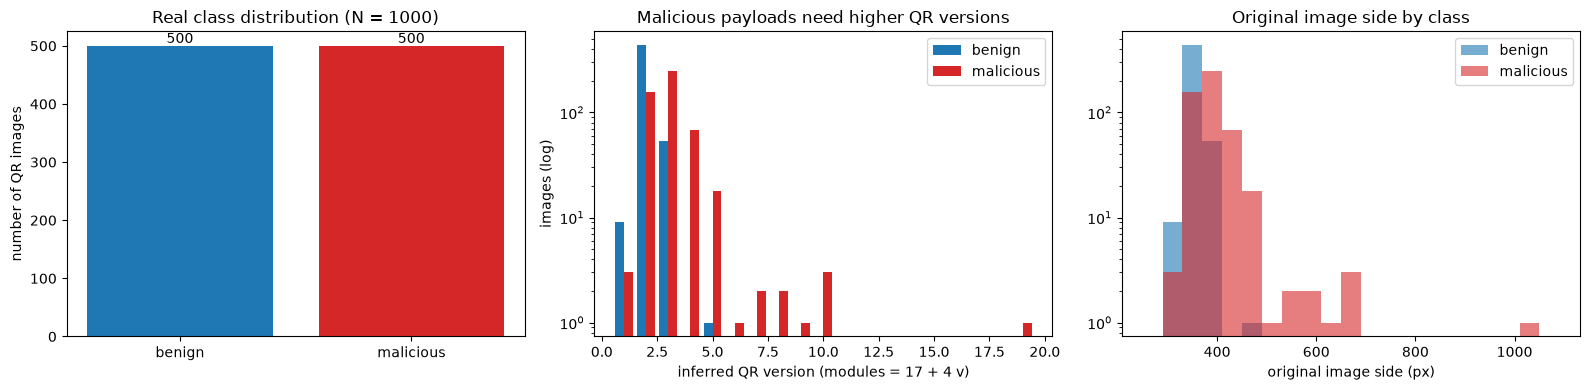

Mean inferred QR version  benign: 2.09 | malicious: 3.01


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].bar(CLASS_NAMES, cnt.values, color=[C_BEN, C_MAL]); axs[0].set_title("Real class distribution (N = %d)" % N)
axs[0].set_ylabel("number of QR images")
for i, v in enumerate(cnt.values): axs[0].text(i, v + 5, str(v), ha="center")
ver = pd.crosstab(meta["qr_version"], y)
w = 0.4
axs[1].bar(ver.index - w/2, ver[0], width=w, color=C_BEN, label="benign")
axs[1].bar(ver.index + w/2, ver[1], width=w, color=C_MAL, label="malicious")
axs[1].set_yscale("log"); axs[1].set_xlabel("inferred QR version (modules = 17 + 4 v)"); axs[1].set_ylabel("images (log)")
axs[1].set_title("Malicious payloads need higher QR versions"); axs[1].legend()
for lab, col, nm in [(0, C_BEN, "benign"), (1, C_MAL, "malicious")]:
    axs[2].hist(meta.loc[y == lab, "orig_size"], bins=np.arange(250, 1100, 40), alpha=.6, color=col, label=nm)
axs[2].set_yscale("log"); axs[2].set_xlabel("original image side (px)"); axs[2].set_title("Original image side by class"); axs[2].legend()
plt.tight_layout(); plt.show()
print("Mean inferred QR version  benign: %.2f | malicious: %.2f" % (meta.loc[y == 0, "qr_version"].mean(), meta.loc[y == 1, "qr_version"].mean()))

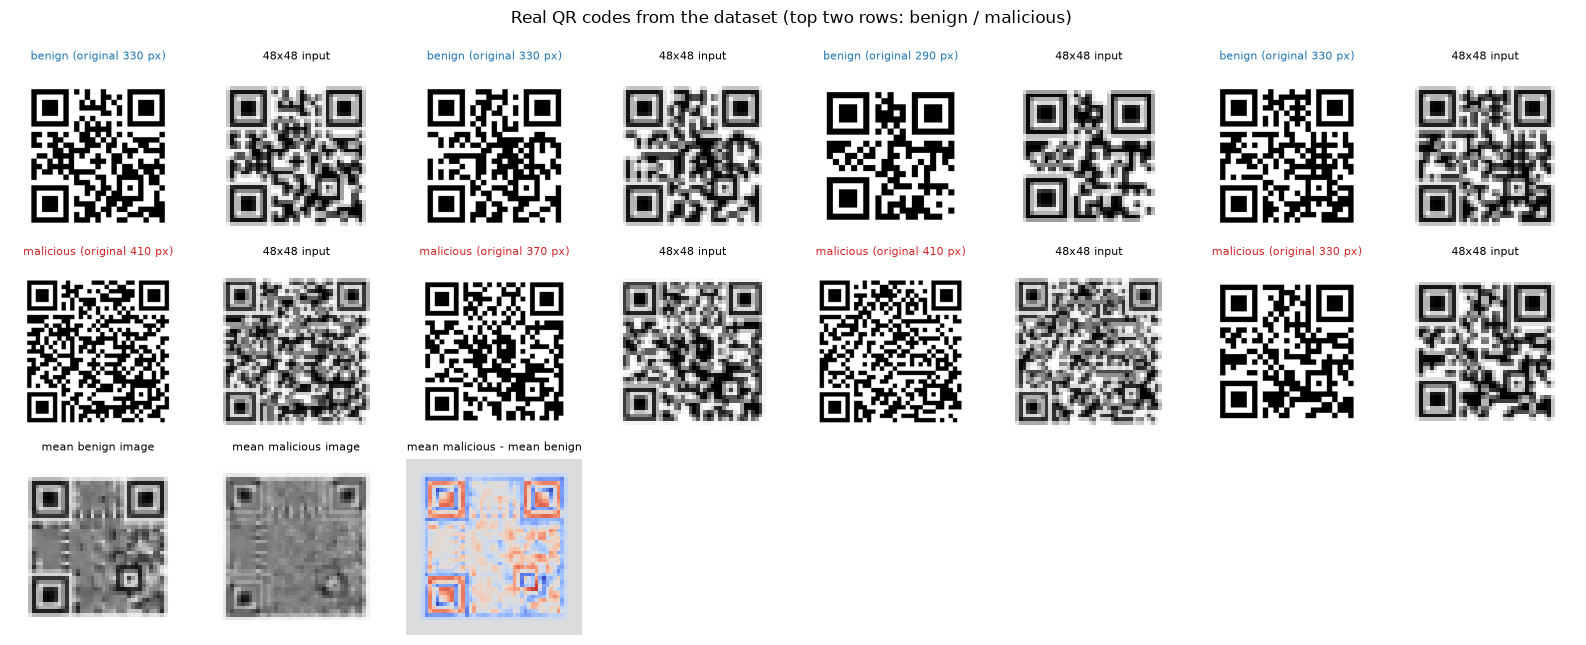

In [8]:
# Real examples as the network sees them (48x48, bilinear) next to the original image, and the class-mean images
fig, axs = plt.subplots(3, 8, figsize=(16, 6.4))
ex_rng = np.random.default_rng(SEED)
for r, lab in enumerate([0, 1]):
    ids = ex_rng.choice(np.where(y == lab)[0], 4, replace=False)
    for k, i in enumerate(ids):
        axs[r, 2*k].imshow(Image.open(meta.loc[i, "path"]).convert("L"), cmap="gray")
        axs[r, 2*k].set_title(f"{CLASS_NAMES[lab]} (original {meta.loc[i,'orig_size']} px)", fontsize=8, color=[C_BEN, C_MAL][lab])
        axs[r, 2*k+1].imshow(X[i], cmap="gray", vmin=-1, vmax=1); axs[r, 2*k+1].set_title("48x48 input", fontsize=8)
for k, lab in enumerate([0, 1]):
    axs[2, k].imshow(X[y == lab].mean(0), cmap="gray", vmin=-1, vmax=1); axs[2, k].set_title(f"mean {CLASS_NAMES[lab]} image", fontsize=8)
diff = X[y == 1].mean(0) - X[y == 0].mean(0)
im = axs[2, 2].imshow(diff, cmap="coolwarm", vmin=-np.abs(diff).max(), vmax=np.abs(diff).max()); axs[2, 2].set_title("mean malicious - mean benign", fontsize=8)
for a in axs.ravel(): a.axis("off")
plt.suptitle("Real QR codes from the dataset (top two rows: benign / malicious)", y=1.0); plt.tight_layout(); plt.show()

### Splits (paper, Section 4.2)

The 1000 images are split by stratified sampling into 70 % training, 15 % validation and 15 % held-out test. Five-fold stratified
cross-validation is then run on the union of training and validation (850 images); inside each fold 80 % / 20 % are fold-training /
fold-validation. The same folds and the same test set are used for every model, so all comparisons are paired.

In [9]:
idx_all = np.arange(N)
idx_pool, idx_test = train_test_split(idx_all, test_size=TEST_FRACTION, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_pool, test_size=VAL_FRACTION / (1 - TEST_FRACTION), stratify=y[idx_pool], random_state=SEED)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = [(idx_pool[a], idx_pool[b]) for a, b in skf.split(idx_pool, y[idx_pool])]      # (fold-train, fold-val) as global indices
print(f"train {len(idx_train)} | validation {len(idx_val)} | test {len(idx_test)} | CV pool {len(idx_pool)}")
for nm, ix in [("train", idx_train), ("val", idx_val), ("test", idx_test), ("pool", idx_pool)]:
    print(f"  {nm:5s} malicious share = {y[ix].mean():.3f}")
print(f"{N_FOLDS}-fold CV: fold-train {len(folds[0][0])} / fold-val {len(folds[0][1])} images per fold")
assert len(set(idx_test) & set(idx_pool)) == 0 and all(len(set(a) & set(b)) == 0 for a, b in folds)

train 700 | validation 150 | test 150 | CV pool 850
  train malicious share = 0.500
  val   malicious share = 0.500
  test  malicious share = 0.500
  pool  malicious share = 0.500
3-fold CV: fold-train 566 / fold-val 284 images per fold


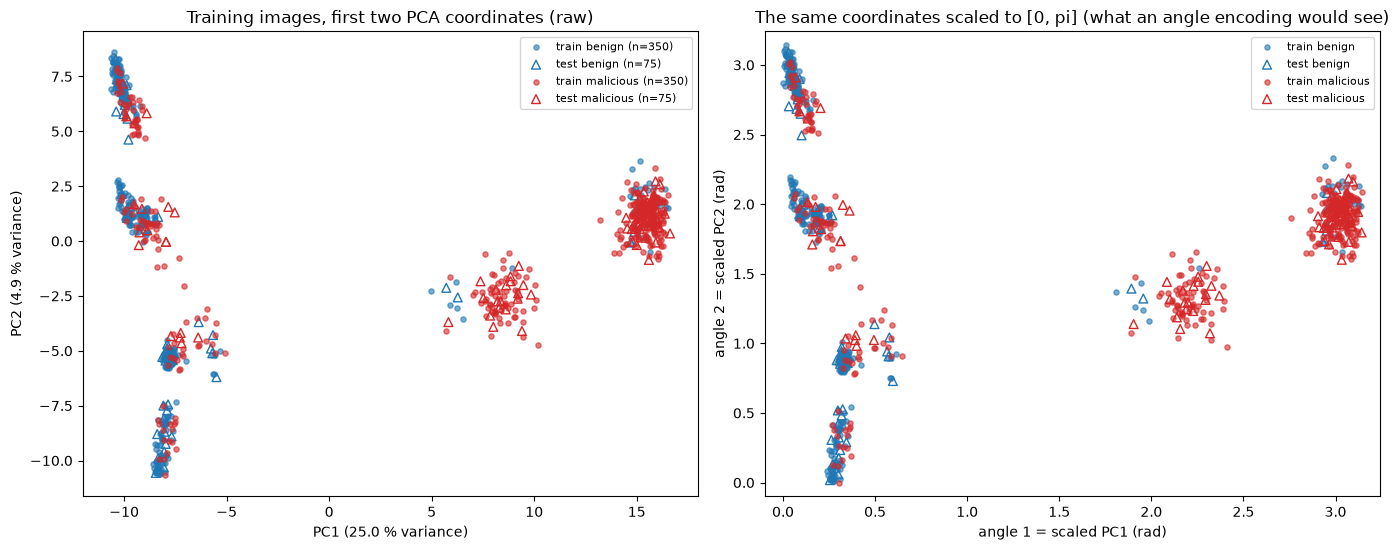

Note: this paper does not feed PCA angles to the circuit. Its angles are the CNN's own tanh outputs (learned end to end);
they are plotted in Section 6 (learned angles). The PCA view above only shows how separable the raw pixels are in 2-D.


In [10]:
# 2-D scatter of the real images coloured by ground-truth label. PCA is fitted on the training split only.
Xflat = X.reshape(N, -1)
pca2 = PCA(n_components=2, random_state=SEED).fit(Xflat[idx_train])
P_tr, P_te = pca2.transform(Xflat[idx_train]), pca2.transform(Xflat[idx_test])
ev = pca2.explained_variance_ratio_
fig, axs = plt.subplots(1, 2, figsize=(14, 5.6))
ax = axs[0]
for lab, col in [(0, C_BEN), (1, C_MAL)]:
    m = y[idx_train] == lab; ax.scatter(P_tr[m, 0], P_tr[m, 1], s=14, alpha=.6, c=col, label=f"train {CLASS_NAMES[lab]} (n={m.sum()})")
    m = y[idx_test] == lab; ax.scatter(P_te[m, 0], P_te[m, 1], s=40, facecolors="none", edgecolors=col, marker="^", label=f"test {CLASS_NAMES[lab]} (n={m.sum()})")
ax.set_xlabel(f"PC1 ({ev[0]*100:.1f} % variance)"); ax.set_ylabel(f"PC2 ({ev[1]*100:.1f} % variance)")
ax.set_title("Training images, first two PCA coordinates (raw)"); ax.legend(fontsize=8)
# the same two coordinates scaled to [0, pi] (scaler fitted on the training split, test angles clipped)
sc = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr, A_te = sc.transform(P_tr), np.clip(sc.transform(P_te), 0, np.pi)
ax = axs[1]
for lab, col in [(0, C_BEN), (1, C_MAL)]:
    m = y[idx_train] == lab; ax.scatter(A_tr[m, 0], A_tr[m, 1], s=14, alpha=.6, c=col, label=f"train {CLASS_NAMES[lab]}")
    m = y[idx_test] == lab; ax.scatter(A_te[m, 0], A_te[m, 1], s=40, facecolors="none", edgecolors=col, marker="^", label=f"test {CLASS_NAMES[lab]}")
ax.set_xlabel("angle 1 = scaled PC1 (rad)"); ax.set_ylabel("angle 2 = scaled PC2 (rad)"); ax.set_xlim(-.1, np.pi + .1); ax.set_ylim(-.1, np.pi + .1)
ax.set_title("The same coordinates scaled to [0, pi] (what an angle encoding would see)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Note: this paper does not feed PCA angles to the circuit. Its angles are the CNN's own tanh outputs (learned end to end);")
print("they are plotted in Section 6 (learned angles). The PCA view above only shows how separable the raw pixels are in 2-D.")

## 2. Tensors, augmentation and metrics

All images are already normalised to [-1, 1] (training-set independent: a fixed linear map, no statistics are fitted, so there is no
leakage). Augmentation (Section 4.3) is applied to training batches only: random crop of up to 8 % of the image, rotation within
+/-8 degrees, brightness and contrast jitter and light Gaussian blur; no flips (they would mirror the finder patterns). We implement the
crop and rotation jointly as one random affine warp (zoom in by the crop fraction, shift inside the removed margin) so the whole
batch is augmented in one tensor operation.

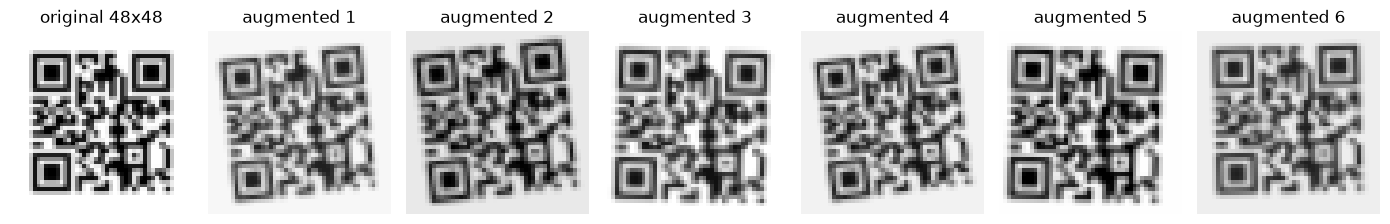

In [11]:
Xt = torch.from_numpy(X).unsqueeze(1)          # (N, 1, 48, 48) float32 in [-1, 1]
yt = torch.from_numpy(y).float()
BLUR_K = torch.tensor([1., 2., 1.]); BLUR_K = (BLUR_K[:, None] * BLUR_K[None, :]); BLUR_K = (BLUR_K / BLUR_K.sum()).view(1, 1, 3, 3)

def augment(xb, gen):
    """Random crop <= 8 % (zoom + shift), rotation +/-8 deg, brightness/contrast jitter, light blur (p = 0.3). Training only."""
    B = xb.shape[0]
    u = lambda lo, hi, *shape: lo + (hi - lo) * torch.rand(*(shape or (B,)), generator=gen)
    ang = u(-8., 8.) * math.pi / 180
    crop = u(0., 0.08)                                              # CHOICE: fraction of the image cropped away
    zoom = 1 - crop
    tx, ty = u(-1., 1.) * crop, u(-1., 1.) * crop
    c, s = torch.cos(ang) * zoom, torch.sin(ang) * zoom
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
    grid = F.affine_grid(theta, xb.shape, align_corners=False)
    out = F.grid_sample(xb, grid, mode="bilinear", padding_mode="border", align_corners=False)
    contrast = u(0.8, 1.2, B, 1, 1, 1); bright = u(-0.1, 0.1, B, 1, 1, 1)
    out = (out * contrast + bright).clamp(-1, 1)
    blurred = F.conv2d(F.pad(out, (1, 1, 1, 1), mode="replicate"), BLUR_K)
    use_blur = (torch.rand(B, 1, 1, 1, generator=gen) < 0.3)
    return torch.where(use_blur, blurred, out)

def metric_dict(y_true, prob):
    yhat = (prob >= 0.5).astype(int)
    return {"acc": accuracy_score(y_true, yhat),
            "prec": precision_score(y_true, yhat, average="macro", zero_division=0),
            "rec": recall_score(y_true, yhat, average="macro", zero_division=0),
            "f1": f1_score(y_true, yhat, average="macro", zero_division=0),
            "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) > 1 else float("nan"),
            "prec_mal": precision_score(y_true, yhat, zero_division=0),
            "rec_mal": recall_score(y_true, yhat, zero_division=0),
            "f1_mal": f1_score(y_true, yhat, zero_division=0)}

# look at what augmentation does to one real training image
g = torch.Generator().manual_seed(SEED)
i0 = int(idx_train[0]); batch = Xt[i0:i0+1].repeat(6, 1, 1, 1)
aug = augment(batch, g)
fig, axs = plt.subplots(1, 7, figsize=(14, 2.3))
axs[0].imshow(Xt[i0, 0], cmap="gray", vmin=-1, vmax=1); axs[0].set_title("original 48x48")
for k in range(6):
    axs[k+1].imshow(aug[k, 0], cmap="gray", vmin=-1, vmax=1); axs[k+1].set_title(f"augmented {k+1}")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper's variational circuit (Section 3.2.2, Eq. 3-5, Fig. 1) acts on `n_q` qubits:

1. a Hadamard on every qubit, then **angle embedding** `RY(z_i)` with the CNN's tanh outputs `z_i in [-1, 1]` (so the state is `RY(z) H |0>`);
2. `L` **variational layers**; each applies a trainable `RY(theta_{l,i,0})` then `RZ(theta_{l,i,1})` on every qubit, followed by a **CNOT ladder**
   `CNOT(0,1), CNOT(1,2), ..., CNOT(n_q-2, n_q-1)`;
3. **measurement** of the Pauli-Z expectation value on every qubit, giving `q in [-1, 1]^{n_q}`, which goes to the classification head
   (standard HQCNN) or is concatenated with `z` (HybridSkip).

Two distinct circuits occur in the six configurations: (4 qubits, 3 layers, 24 trainable angles) and (6 qubits, 4 layers, 48 trainable
angles). The cells below build exactly this circuit as a **PennyLane QNode on `default.qubit`** (the paper's simulator), draw the QNode that is
executed, print qubit count / depth / trainable parameters, and then prove that the fast PyTorch implementation used for the long training runs is the same
function (outputs and gradients). The paper does not state the initial weights (we use uniform on [0, 2 pi)), and the CNOT ladder is open
(no wrap-around CNOT), as in Fig. 1 and Eq. 4.

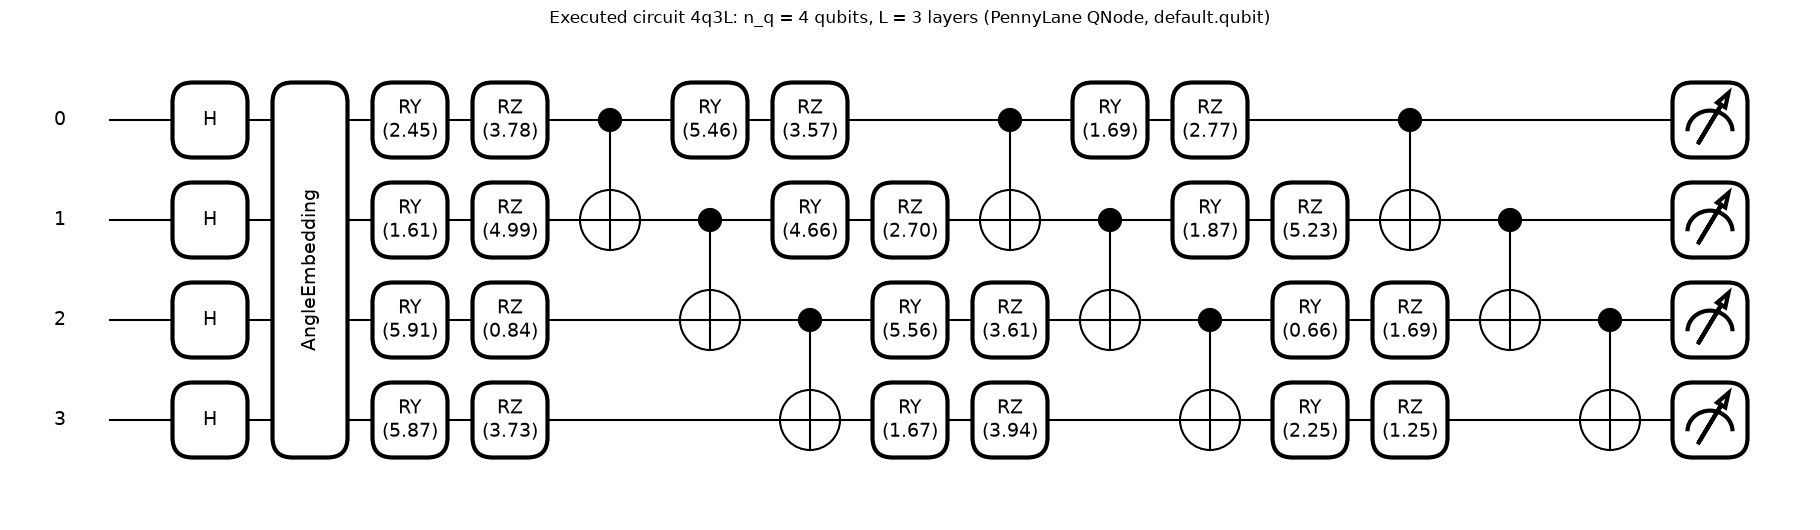

4q3L: qubits = 4 | depth (PennyLane specs) = 15 (layer-by-layer upper bound 2 + L(n_q+1) = 17; successive ladders overlap) | trainable parameters = 24 (= 2 n_q L = 24) | CNOTs = 9 | measured observables = 4 x PauliZ


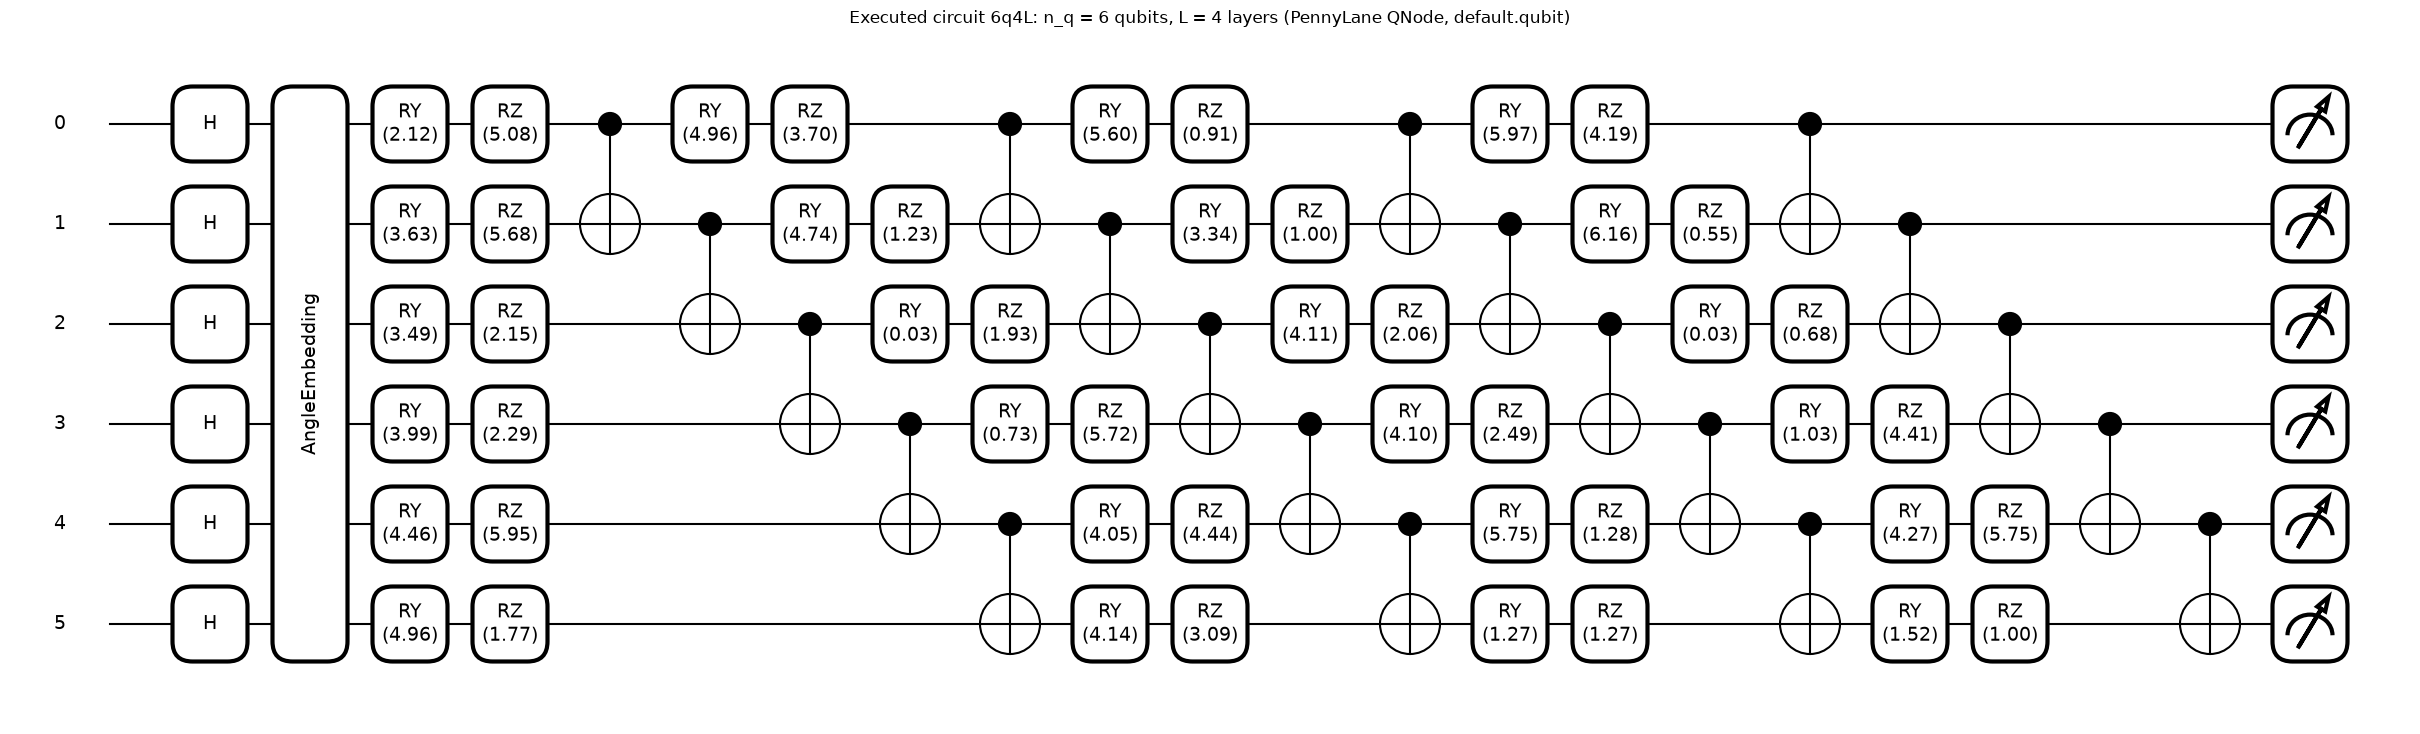

6q4L: qubits = 6 | depth (PennyLane specs) = 21 (layer-by-layer upper bound 2 + L(n_q+1) = 30; successive ladders overlap) | trainable parameters = 48 (= 2 n_q L = 48) | CNOTs = 20 | measured observables = 6 x PauliZ


In [12]:
def make_qnode(nq):
    dev = qml.device("default.qubit", wires=nq)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        for i in range(nq):                                   # |psi_0> = (x)_i RY(z_i) H |0>      (Eq. 3)
            qml.Hadamard(wires=i)
        qml.AngleEmbedding(inputs, wires=range(nq), rotation="Y")
        for l in range(weights.shape[0]):                     # U_l = CNOT ladder . prod_i RZ(theta_l,i,1) RY(theta_l,i,0)   (Eq. 4)
            for i in range(nq):
                qml.RY(weights[l, i, 0], wires=i)
                qml.RZ(weights[l, i, 1], wires=i)
            for i in range(nq - 1):
                qml.CNOT(wires=[i, i + 1])
        return [qml.expval(qml.PauliZ(i)) for i in range(nq)]   # q_i = <Z_i>   (Eq. 5)
    return circuit

ARCH = {"4q3L": (4, 3), "6q4L": (6, 4)}
QNODES = {k: make_qnode(nq) for k, (nq, L) in ARCH.items()}
demo_rng = torch.Generator().manual_seed(SEED)
for key, (nq, L) in ARCH.items():
    x_demo = torch.rand(nq, generator=demo_rng) * 2 - 1                          # one example tanh output z
    w_demo = torch.rand(L, nq, 2, generator=demo_rng) * 2 * math.pi              # CHOICE: init uniform [0, 2 pi)
    fig, ax = qml.draw_mpl(QNODES[key], decimals=2, show_all_wires=True)(x_demo, w_demo)
    fig.suptitle(f"Executed circuit {key}: n_q = {nq} qubits, L = {L} layers (PennyLane QNode, default.qubit)", y=1.02)
    plt.show()
    depth_formula = 2 + L * (nq + 1)            # layer-by-layer upper bound: H + embedding (2); per layer RY, RZ, then nq-1 CNOTs in series
    try:
        depth_pl = qml.specs(QNODES[key])(x_demo, w_demo)["resources"].depth
    except Exception as e:
        depth_pl = None
    n_gates_rot = 2 * nq * L
    print(f"{key}: qubits = {nq} | depth (PennyLane specs) = {depth_pl} (layer-by-layer upper bound 2 + L(n_q+1) = {depth_formula}; successive ladders overlap) | "
          f"trainable parameters = {w_demo.numel()} (= 2 n_q L = {n_gates_rot}) | CNOTs = {(nq-1)*L} | measured observables = {nq} x PauliZ")
    if depth_pl is not None:
        assert depth_pl <= depth_formula
    assert w_demo.numel() == 2 * nq * L

In [13]:
# ---- fast exact state-vector implementation of the SAME circuit in PyTorch (batched, differentiable) ----
def cnot_ladder_matrix(nq):
    d = 2 ** nq; M = np.eye(d)
    for i in range(nq - 1):                          # CNOT(i, i+1), applied in order i = 0 .. nq-2 ; wire 0 = most significant bit
        C = np.zeros((d, d))
        for b in range(d):
            bits = [(b >> (nq - 1 - w)) & 1 for w in range(nq)]
            if bits[i] == 1: bits[i + 1] ^= 1
            C[sum(bit << (nq - 1 - w) for w, bit in enumerate(bits)), b] = 1
        M = C @ M
    return torch.from_numpy(M)

def z_signs(nq):
    d = 2 ** nq
    return torch.tensor([[1 - 2 * ((b >> (nq - 1 - w)) & 1) for w in range(nq)] for b in range(d)], dtype=torch.float64)

def vqc_expvals(inputs, weights, P, S):
    """inputs (B, nq) in radians, weights (L, nq, 2) -> <Z_i> (B, nq); exact, same gate list as the QNode above."""
    B, nq = inputs.shape
    cdt = torch.complex128 if inputs.dtype == torch.float64 else torch.complex64
    c, s = torch.cos(inputs / 2), torch.sin(inputs / 2)
    q1 = torch.stack([c - s, c + s], -1) / math.sqrt(2)                       # RY(z) H|0> for each qubit
    psi = q1[:, 0, :]
    for i in range(1, nq):
        psi = (psi[:, :, None] * q1[:, i, None, :]).reshape(B, -1)
    psi = psi.to(cdt)
    th, ph = weights[..., 0], weights[..., 1]
    ct, st = torch.cos(th / 2), torch.sin(th / 2)
    em = torch.polar(torch.ones_like(ph), -ph / 2); ep = torch.polar(torch.ones_like(ph), ph / 2)
    G = torch.stack([torch.stack([em * ct, -em * st], -1), torch.stack([ep * st, ep * ct], -1)], -2)    # RZ . RY, (L, nq, 2, 2)
    Pm = P.to(cdt)
    U = torch.eye(2 ** nq, dtype=cdt)
    for l in range(weights.shape[0]):
        K = G[l, 0]
        for i in range(1, nq):
            K = torch.kron(K, G[l, i])
        U = Pm @ K @ U
    out = psi @ U.T
    probs = out.real ** 2 + out.imag ** 2
    return probs @ S.to(probs.dtype)

# ---- equivalence check against the PennyLane QNode: outputs and gradients (float64) ----
chk = torch.Generator().manual_seed(SEED + 1)
for key, (nq, L) in ARCH.items():
    P, S = cnot_ladder_matrix(nq), z_signs(nq)
    xin = (torch.rand(5, nq, generator=chk, dtype=torch.float64) * 2 - 1).requires_grad_(True)
    win = (torch.rand(L, nq, 2, generator=chk, dtype=torch.float64) * 2 * math.pi).requires_grad_(True)
    out_pl = torch.stack(QNODES[key](xin, win), dim=1)
    g_pl = torch.autograd.grad((out_pl * torch.arange(1, nq + 1)).sum(), [xin, win])
    out_fast = vqc_expvals(xin, win, P, S)
    g_fast = torch.autograd.grad((out_fast * torch.arange(1, nq + 1)).sum(), [xin, win])
    d_out = (out_pl - out_fast).abs().max().item(); d_g = max((a - b).abs().max().item() for a, b in zip(g_pl, g_fast))
    print(f"{key}: max |PennyLane - fast| outputs = {d_out:.2e}, gradients (inputs and weights) = {d_g:.2e}")
    assert d_out < 1e-9 and d_g < 1e-9
print("The fast PyTorch simulator and the PennyLane QNode compute the same expectation values and the same gradients.")

4q3L: max |PennyLane - fast| outputs = 1.11e-15, gradients (inputs and weights) = 3.11e-15


6q4L: max |PennyLane - fast| outputs = 7.77e-16, gradients (inputs and weights) = 1.07e-14
The fast PyTorch simulator and the PennyLane QNode compute the same expectation values and the same gradients.


## 3. The six models

All six share the convolutional backbone (Section 3.2.1). They differ only in what sits between the projection `z in [-1,1]^{n_q}` and the
logit:

* **Classical-hH**: the circuit is replaced by `Linear(H, H) + tanh`, then the wide head.
* **HQCNN-nqL**: variational circuit -> `q = <Z>` -> wide head `Linear(n_q, W) - ReLU - Dropout - Linear(W, 1)`.
* **HybridSkip-nqL**: variational circuit -> `h = [q ; z]` -> `Linear(2 n_q, 8) - ReLU - Dropout - Linear(8, 1)` (Eq. 7-9).

The width `W` of the wide head is not given in the paper; we pick it per model so that the total parameter count equals the paper's
Table 5 count for that model (CHOICE). The cell also prints what the literal Fig. 1 backbone would cost.

In [14]:
class VQCLayer(nn.Module):
    def __init__(self, nq, L):
        super().__init__()
        self.nq, self.L = nq, L
        self.weights = nn.Parameter(torch.rand(L, nq, 2) * 2 * math.pi)       # CHOICE: uniform [0, 2 pi)
        self.register_buffer("P", cnot_ladder_matrix(nq)); self.register_buffer("S", z_signs(nq))
    def forward(self, z):
        return vqc_expvals(z, self.weights, self.P, self.S)

class QRNet(nn.Module):
    def __init__(self, kind, nq, L, wide=64, widths=WIDTHS, fc=FC_HIDDEN):
        super().__init__()
        a, a2, b, b2, c = widths
        cb = lambda i, o: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
        self.backbone = nn.Sequential(*cb(1, a), *cb(a, a2), nn.MaxPool2d(2), nn.Dropout2d(0.1),
                                      *cb(a2, b), *cb(b, b2), nn.MaxPool2d(2), nn.Dropout2d(0.2),
                                      *cb(b2, c), nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(c, fc), nn.ReLU(), nn.Dropout(0.3), nn.Linear(fc, nq), nn.Tanh())   # z in [-1,1]^nq (Eq. 2)
        self.kind = kind
        if kind == "classical":
            self.mid = nn.Sequential(nn.Linear(nq, nq), nn.Tanh()); d_in, hid = nq, wide
        elif kind == "hqcnn":
            self.mid = VQCLayer(nq, L); d_in, hid = nq, wide
        else:
            self.mid = VQCLayer(nq, L); d_in, hid = 2 * nq, 8
        self.head = nn.Sequential(nn.Linear(d_in, hid), nn.ReLU(), nn.Dropout(0.2), nn.Linear(hid, 1))
    def features(self, x):
        return self.backbone(x)
    def forward(self, x):
        z = self.backbone(x)
        q = self.mid(z)
        h = torch.cat([q, z], 1) if self.kind == "skip" else q
        return self.head(h).squeeze(1)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def build_model(name, wide=None):
    kind, nq, L = MODELS[name]
    if kind == "skip":
        return QRNet(kind, nq, L)
    if wide is None:                                           # CHOICE: size the wide head to the paper's parameter total
        p1 = n_params(QRNet(kind, nq, L, wide=1)); slope = n_params(QRNet(kind, nq, L, wide=2)) - p1
        wide = max(1, int(round((PAPER_PARAMS[name] - p1) / slope)) + 1)
    return QRNet(kind, nq, L, wide=wide)

rows = []
for name in MODELS:
    m = build_model(name)
    kind, nq, L = MODELS[name]
    rows.append({"model": name, "kind": kind, "n_q / H": nq, "layers": L, "circuit angles": 2 * nq * L if kind != "classical" else 0,
                 "wide head W": (m.head[0].out_features if kind != "skip" else "-"), "trainable params": n_params(m), "paper params": PAPER_PARAMS[name]})
param_table = pd.DataFrame(rows).set_index("model")
display(param_table)
lit = QRNet("skip", 6, 4, widths=(32, 32, 64, 64, 128), fc=64)
print(f"For comparison: the LITERAL Fig. 1 backbone (32-32-64-64-128, FC 128->64->6) makes HybridSkip-6q4L a {n_params(lit):,}-parameter model, "
      f"not 21,015 -> the paper's parameter totals cannot come from Fig. 1 as drawn.")
red = 1 - param_table.loc["HybridSkip-6q4L", "trainable params"] / param_table.loc["Classical-h8", "trainable params"]
print(f"HybridSkip-6q4L vs Classical-h8 parameter reduction in this notebook: {red*100:.1f} % (paper: 37.6 %; wide heads are calibrated to the paper's totals)")

,kind,n_q / H,layers,circuit angles,wide head W,trainable params,paper params
model,,,,,,,
Classical-h4,classical,4,0,0,2084,33285,33285
Classical-h8,classical,8,0,0,1277,33671,33673
HQCNN-4q3L,hqcnn,4,3,24,2110,33445,33445
HQCNN-6q4L,hqcnn,6,4,48,1609,33715,33719
HybridSkip-4q3L,skip,4,3,24,-,20865,19861
HybridSkip-6q4L,skip,6,4,48,-,20955,21015


For comparison: the LITERAL Fig. 1 backbone (32-32-64-64-128, FC 128->64->6) makes HybridSkip-6q4L a 148,295-parameter model, not 21,015 -> the paper's parameter totals cannot come from Fig. 1 as drawn.
HybridSkip-6q4L vs Classical-h8 parameter reduction in this notebook: 37.8 % (paper: 37.6 %; wide heads are calibrated to the paper's totals)


## 4. Training protocol

One `fit` call implements Section 3.4 and 4.4: Adam (lr 1e-3, weight decay 1e-4), cosine annealing over `MAX_EPOCHS`, binary cross-entropy with logits,
gradient clipping at norm 1.0, batch size 8, augmentation on training batches only, and early stopping on the validation macro-F1 with the
best checkpoint restored. The same seed is used for every fit (paper: seed 42 across folds and configurations).

In [15]:
def predict_proba(model, idx, bs=256):
    model.eval(); out = []
    with torch.no_grad():
        for s in range(0, len(idx), bs):
            out.append(torch.sigmoid(model(Xt[idx[s:s+bs]])))
    return torch.cat(out).numpy()

def fit(name, tr_idx, va_idx, seed=SEED, verbose=False):
    torch.manual_seed(seed)
    model = build_model(name)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
    gen = torch.Generator().manual_seed(seed)
    best_f1, best_state, bad, hist = -1.0, None, 0, []
    t0 = time.time()
    for ep in range(MAX_EPOCHS):
        model.train(); perm = tr_idx[torch.randperm(len(tr_idx), generator=gen).numpy()]; tot, nb = 0.0, 0
        for s in range(0, len(perm), BATCH_SIZE):
            bi = perm[s:s + BATCH_SIZE]
            if len(bi) < 2: continue
            xb = augment(Xt[bi], gen)
            loss = F.binary_cross_entropy_with_logits(model(xb), yt[bi])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM); opt.step()
            tot += loss.item(); nb += 1
        sched.step()
        pv = predict_proba(model, va_idx); f1v = f1_score(y[va_idx], (pv >= .5).astype(int), average="macro")
        hist.append({"epoch": ep + 1, "train_loss": tot / max(nb, 1), "val_f1": f1v})
        if f1v > best_f1:
            best_f1, best_state, bad = f1v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if verbose: print(f"  ep {ep+1:2d} loss {tot/nb:.4f} val-F1 {f1v:.3f}")
        if bad >= PATIENCE: break
    model.load_state_dict(best_state)              # restore the checkpoint with the best validation F1
    return model, pd.DataFrame(hist), time.time() - t0

# quick smoke test + timing of one epoch for the biggest quantum model (not used in the results)
_t = time.time(); _m, _h, _s = fit("HybridSkip-6q4L", folds[0][0][:96], folds[0][1][:40]);
print(f"smoke test fit on 96 images: {_s:.1f} s for {len(_h)} epochs -> ~{_s/len(_h)/96*680:.1f} s per epoch at 680 training images")

smoke test fit on 96 images: 8.6 s for 3 epochs -> ~20.4 s per epoch at 680 training images


## 5. Stratified five-fold cross-validation (Table 2)

For each of the six models and each fold we train on the fold-training part, early-stop on the fold-validation part, restore the best checkpoint and compute
accuracy, macro precision / recall / F1 and AUC on the fold-validation part (the paper's protocol). As an extra the same fold model is scored on the
untouched held-out test set (not used for any selection), which gives an unbiased number per fold.

In [16]:
cv_rows, hist_store = [], {}
t_cv = time.time()
for k, (tr, va) in enumerate(folds):
    for name in MODELS:
        model, hist, secs = fit(name, tr, va)
        pv = predict_proba(model, va); pt = predict_proba(model, idx_test)
        mv = metric_dict(y[va], pv); mt = metric_dict(y[idx_test], pt)
        cv_rows.append({"model": name, "fold": k, **mv, **{"test_" + a: b for a, b in mt.items()}, "epochs": len(hist), "secs": secs})
        hist_store[(name, k)] = hist
        print(f"fold {k+1}/{N_FOLDS} {name:16s} epochs {len(hist):2d} | val acc {mv['acc']:.3f} F1 {mv['f1']:.3f} rec {mv['rec']:.3f} AUC {mv['auc']:.3f} | test F1 {mt['f1']:.3f} | {secs:5.0f}s")
cv = pd.DataFrame(cv_rows)
print(f"\nCross-validation finished in {(time.time()-t_cv)/60:.1f} min")

fold 1/3 Classical-h4     epochs  4 | val acc 0.750 F1 0.746 rec 0.750 AUC 0.781 | test F1 0.839 |    63s


fold 1/3 Classical-h8     epochs  4 | val acc 0.616 F1 0.558 rec 0.616 AUC 0.801 | test F1 0.610 |    39s


fold 1/3 HQCNN-4q3L       epochs  4 | val acc 0.570 F1 0.477 rec 0.570 AUC 0.796 | test F1 0.551 |    45s


fold 1/3 HQCNN-6q4L       epochs  4 | val acc 0.750 F1 0.746 rec 0.750 AUC 0.799 | test F1 0.839 |    56s


fold 1/3 HybridSkip-4q3L  epochs  4 | val acc 0.553 F1 0.445 rec 0.553 AUC 0.777 | test F1 0.530 |    50s


...

fold 3/3 Classical-h8     epochs  4 | val acc 0.792 F1 0.791 rec 0.791 AUC 0.799 | test F1 0.839 |    43s


fold 3/3 HQCNN-4q3L       epochs  4 | val acc 0.802 F1 0.801 rec 0.802 AUC 0.807 | test F1 0.839 |    52s


fold 3/3 HQCNN-6q4L       epochs  4 | val acc 0.799 F1 0.797 rec 0.798 AUC 0.816 | test F1 0.832 |    72s


fold 3/3 HybridSkip-4q3L  epochs  4 | val acc 0.784 F1 0.784 rec 0.784 AUC 0.791 | test F1 0.839 |    54s


fold 3/3 HybridSkip-6q4L  epochs  4 | val acc 0.608 F1 0.535 rec 0.606 AUC 0.798 | test F1 0.551 |    60s

Cross-validation finished in 14.4 min


In [17]:
def mean_std(df, cols=("acc", "prec", "rec", "f1", "auc")):
    g = df.groupby("model", sort=False)
    return pd.DataFrame({c: g[c].mean().round(3).astype(str) + " +/- " + g[c].std().round(3).astype(str) for c in cols})[list(cols)]
print("Table 2 re-computed (mean +/- std over folds, macro-averaged, fold-validation sets):")
table2 = mean_std(cv); display(table2)
cv_mean = cv.groupby("model", sort=False)[["acc", "prec", "rec", "f1", "auc", "prec_mal", "rec_mal", "f1_mal", "test_acc", "test_f1", "test_rec", "test_auc", "epochs", "secs"]].mean()
print("Same folds, malicious class only (precision / recall / F1) and the same fold models on the untouched test set:")
display(cv_mean[["prec_mal", "rec_mal", "f1_mal", "test_acc", "test_rec", "test_f1", "test_auc", "epochs", "secs"]].round(3))

Table 2 re-computed (mean +/- std over folds, macro-averaged, fold-validation sets):


,acc,prec,rec,f1,auc
model,,,,,
Classical-h4,0.734 +/- 0.077,0.776 +/- 0.032,0.734 +/- 0.076,0.72 +/- 0.097,0.803 +/- 0.027
Classical-h8,0.675 +/- 0.101,0.774 +/- 0.026,0.676 +/- 0.1,0.635 +/- 0.135,0.788 +/- 0.02
HQCNN-4q3L,0.634 +/- 0.147,0.771 +/- 0.034,0.635 +/- 0.146,0.559 +/- 0.213,0.802 +/- 0.005
HQCNN-6q4L,0.716 +/- 0.103,0.784 +/- 0.02,0.717 +/- 0.102,0.69 +/- 0.144,0.807 +/- 0.009
HybridSkip-4q3L,0.612 +/- 0.152,0.591 +/- 0.297,0.612 +/- 0.151,0.52 +/- 0.235,0.714 +/- 0.122
HybridSkip-6q4L,0.648 +/- 0.048,0.75 +/- 0.041,0.648 +/- 0.048,0.607 +/- 0.084,0.781 +/- 0.038


Same folds, malicious class only (precision / recall / F1) and the same fold models on the untouched test set:


,prec_mal,rec_mal,f1_mal,test_acc,test_rec,test_f1,test_auc,epochs,secs
model,,,,,,,,,
Classical-h4,0.869,0.558,0.663,0.784,0.784,0.773,0.880,4.000,44.409
Classical-h8,0.916,0.410,0.521,0.707,0.707,0.672,0.861,3.667,36.197
HQCNN-4q3L,0.937,0.312,0.387,0.664,0.664,0.602,0.877,4.000,44.102
HQCNN-6q4L,0.898,0.513,0.611,0.764,0.764,0.742,0.851,4.000,57.938
HybridSkip-4q3L,0.588,0.279,0.324,0.647,0.647,0.567,0.772,3.667,48.904
HybridSkip-6q4L,0.894,0.381,0.492,0.680,0.680,0.643,0.859,3.667,43.107


## 6. Held-out test set (Table 3)

"Models retrained on the full training pool with the hyper-parameters selected by cross-validation": each model is retrained on the 850-image pool
(10 % of it used for early stopping, our choice) and scored once on the 150 test images.

In [18]:
held, held_prob, held_models = [], {}, {}
t_h = time.time()
pool_tr, pool_es = train_test_split(idx_pool, test_size=HELDOUT_ES_FRACTION, stratify=y[idx_pool], random_state=SEED)
for name in MODELS:
    model, hist, secs = fit(name, pool_tr, pool_es)
    pt = predict_proba(model, idx_test); held_prob[name] = pt; held_models[name] = model; hist_store[(name, "held")] = hist
    mt = metric_dict(y[idx_test], pt); held.append({"model": name, **mt, "params": n_params(model), "epochs": len(hist), "secs": secs})
    print(f"{name:16s} test acc {mt['acc']:.3f} prec {mt['prec']:.3f} rec {mt['rec']:.3f} F1 {mt['f1']:.3f} AUC {mt['auc']:.3f} ({len(hist)} epochs, {secs:.0f}s)")
held = pd.DataFrame(held).set_index("model")
print(f"\nheld-out retraining finished in {(time.time()-t_h)/60:.1f} min")
print("Table 3 re-computed:"); display(held[["acc", "prec", "rec", "f1", "auc", "prec_mal", "rec_mal", "f1_mal", "params"]].round(3))

Classical-h4     test acc 0.747 prec 0.810 rec 0.747 F1 0.733 AUC 0.891 (4 epochs, 69s)


Classical-h8     test acc 0.540 prec 0.760 rec 0.540 F1 0.417 AUC 0.852 (3 epochs, 58s)


HQCNN-4q3L       test acc 0.840 prec 0.852 rec 0.840 F1 0.839 AUC 0.876 (4 epochs, 78s)


HQCNN-6q4L       test acc 0.840 prec 0.852 rec 0.840 F1 0.839 AUC 0.866 (4 epochs, 83s)


HybridSkip-4q3L  test acc 0.720 prec 0.786 rec 0.720 F1 0.703 AUC 0.880 (4 epochs, 84s)


HybridSkip-6q4L  test acc 0.840 prec 0.852 rec 0.840 F1 0.839 AUC 0.855 (4 epochs, 101s)

held-out retraining finished in 8.0 min
Table 3 re-computed:


,acc,prec,rec,f1,auc,prec_mal,rec_mal,f1_mal,params
model,,,,,,,,,
Classical-h4,0.747,0.810,0.747,0.733,0.891,0.951,0.520,0.672,33285
Classical-h8,0.540,0.760,0.540,0.417,0.852,1.000,0.080,0.148,33671
HQCNN-4q3L,0.840,0.852,0.840,0.839,0.876,0.918,0.747,0.824,33445
HQCNN-6q4L,0.840,0.852,0.840,0.839,0.866,0.918,0.747,0.824,33715
HybridSkip-4q3L,0.720,0.786,0.720,0.703,0.880,0.923,0.480,0.632,20865
HybridSkip-6q4L,0.840,0.852,0.840,0.839,0.855,0.918,0.747,0.824,20955


### Classical reference points on the same inputs

Two off-the-shelf classifiers on the identical 48 x 48 inputs (flattened to 2304 numbers), with the same folds and the same test set:
a random forest and an RBF-SVM (`C = 1`). As a diagnostic we also add a one-feature model that sees only the **original image side** (which fixes the QR
version): this information is *not* available to the CNN after resizing, but it tells us how much of the task is "payload length".

In [19]:
Xf = X.reshape(N, -1)
side = meta["orig_size"].to_numpy().reshape(-1, 1).astype(float)
def run_ref(make, feats):
    cvr = []
    for k, (tr, va) in enumerate(folds):
        m = make().fit(feats[tr], y[tr])
        p = m.predict_proba(feats[va])[:, 1] if hasattr(m, "predict_proba") else m.decision_function(feats[va])
        cvr.append(metric_dict(y[va], p if hasattr(m, "predict_proba") else 1 / (1 + np.exp(-p))))
    m = make().fit(feats[idx_pool], y[idx_pool])
    p = m.predict_proba(feats[idx_test])[:, 1] if hasattr(m, "predict_proba") else 1 / (1 + np.exp(-m.decision_function(feats[idx_test])))
    return pd.DataFrame(cvr), metric_dict(y[idx_test], p)
refs = {"RandomForest(300) on pixels": (lambda: RandomForestClassifier(300, random_state=SEED, n_jobs=N_THREADS), Xf),
        "SVC(rbf, C=1) on pixels":     (lambda: SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED), Xf),
        "LogReg on original image side (diagnostic)": (lambda: LogisticRegression(max_iter=1000), (side - side.mean()) / side.std())}
ref_rows, ref_cvf1 = [], {}
for nm, (mk, ft) in refs.items():
    cvr, tst = run_ref(mk, ft)
    ref_cvf1[nm] = cvr["f1"].to_numpy()
    ref_rows.append({"model": nm, "CV acc": f"{cvr.acc.mean():.3f} +/- {cvr.acc.std():.3f}", "CV rec": f"{cvr.rec.mean():.3f} +/- {cvr.rec.std():.3f}",
                     "CV F1": f"{cvr.f1.mean():.3f} +/- {cvr.f1.std():.3f}", "CV AUC": f"{cvr.auc.mean():.3f} +/- {cvr.auc.std():.3f}",
                     "test acc": round(tst["acc"], 3), "test F1": round(tst["f1"], 3), "test rec": round(tst["rec"], 3), "test AUC": round(tst["auc"], 3)})
ref_table = pd.DataFrame(ref_rows).set_index("model"); display(ref_table)

,CV acc,CV rec,CV F1,CV AUC,test acc,test F1,test rec,test AUC
model,,,,,,,,
RandomForest(300) on pixels,0.876 +/- 0.021,0.877 +/- 0.021,0.876 +/- 0.021,0.935 +/- 0.017,0.907,0.907,0.907,0.949
"SVC(rbf, C=1) on pixels",0.822 +/- 0.040,0.822 +/- 0.040,0.822 +/- 0.041,0.905 +/- 0.018,0.873,0.873,0.873,0.935
LogReg on original image side (diagnostic),0.779 +/- 0.027,0.779 +/- 0.026,0.776 +/- 0.028,0.789 +/- 0.028,0.840,0.839,0.840,0.845


## 7. Statistical tests (Table 4)

Paired tests across the cross-validation folds of each quantum model against Classical-h8: paired t-test (two-sided), one-tailed Wilcoxon signed-rank test
(alternative: quantum > classical), Cohen's d and the 95 % confidence interval of the mean fold difference.

In [20]:
def paired_report(a, b):
    d = np.asarray(a) - np.asarray(b); n = len(d); sd = d.std(ddof=1)
    t_p = stats.ttest_rel(a, b).pvalue if sd > 0 else np.nan
    try: w_p = stats.wilcoxon(a, b, alternative="greater").pvalue
    except ValueError: w_p = np.nan
    dz = d.mean() / sd if sd > 0 else np.nan
    h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return {"delta": d.mean(), "t-test p": t_p, "Wilcoxon p (1-tail)": w_p, "Cohen d": dz, "95% CI": f"[{d.mean()-h:+.3f}, {d.mean()+h:+.3f}]"}

fold_vals = {m: {c: cv[cv.model == m].sort_values("fold")[c].to_numpy() for c in ("f1", "rec", "auc")} for m in MODELS}
stat_rows = []
for q in ["HQCNN-6q4L", "HybridSkip-6q4L"]:
    for c, cn in [("f1", "F1"), ("rec", "Recall"), ("auc", "AUC")]:
        stat_rows.append({"comparison": f"{q} vs Classical-h8", "metric": cn, **paired_report(fold_vals[q][c], fold_vals["Classical-h8"][c])})
stat_table = pd.DataFrame(stat_rows).set_index(["comparison", "metric"])
display(stat_table.round(3))
print(f"Only {N_FOLDS} folds: with all differences positive the smallest possible one-tailed Wilcoxon p is 1/2^{N_FOLDS} = {1/2**N_FOLDS:.4f}.")

# internal consistency of the paper's own Table 4 (n = 5 folds). From the reported mean difference and its 95 % CI the t statistic follows:
# half-width = t_crit(4) * sd / sqrt(5)  =>  t = delta / (half-width / t_crit(4)). Compare the implied p-value and paired effect size d_z with the printed ones.
paper_t4 = [  # model, metric, delta, CI low, CI high, printed t-test p, printed Cohen d
    ("HQCNN-6q4L", "F1", .031, .011, .051, .012, 1.15), ("HQCNN-6q4L", "Recall", .053, .022, .084, .009, 1.86), ("HQCNN-6q4L", "AUC", .032, .018, .046, .003, 1.39),
    ("HybridSkip-6q4L", "F1", .022, .000, .044, .049, 0.82), ("HybridSkip-6q4L", "Recall", .045, .015, .075, .014, 1.66), ("HybridSkip-6q4L", "AUC", .019, .005, .033, .020, 0.83)]
chk_rows = []
for m_, c_, dl, lo, hi, p_, d_ in paper_t4:
    half = (hi - lo) / 2; t_ = dl / (half / stats.t.ppf(0.975, 4))
    chk_rows.append({"model": m_, "metric": c_, "paper delta": dl, "paper t-test p": p_, "p implied by the paper's CI": round(2 * stats.t.sf(t_, 4), 3),
                     "paper Cohen d": d_, "paired d_z implied by CI (= t/sqrt(5))": round(t_ / np.sqrt(5), 2)})
print("\nThe paper's printed p-values agree with its own CIs, but its Cohen's d is not the paired d_z (it is probably a pooled-SD d):")
display(pd.DataFrame(chk_rows))

delta  t-test p  Wilcoxon p (1-tail)  Cohen d            95% CI
comparison                      metric                                                                 
HQCNN-6q4L vs Classical-h8      F1      0.055     0.496                0.375    0.477  [-0.233, +0.343]
                                Recall  0.041     0.474                0.375    0.505  [-0.161, +0.243]
                                AUC     0.019     0.274                0.250    0.861  [-0.035, +0.073]
HybridSkip-6q4L vs Classical-h8 F1     -0.028     0.838                0.625   -0.134  [-0.537, +0.482]
                                Recall -0.028     0.766                0.625   -0.197  [-0.376, +0.321]
                                AUC    -0.008     0.827                0.750   -0.143  [-0.138, +0.123]

Only 3 folds: with all differences positive the smallest possible one-tailed Wilcoxon p is 1/2^3 = 0.1250.

The paper's printed p-values agree with its own CIs, but its Cohen's d is not the paired d_z (it is probably a pooled-SD d):


,model,metric,paper delta,paper t-test p,p implied by the paper's CI,paper Cohen d,paired d_z implied by CI (= t/sqrt(5))
0,HQCNN-6q4L,F1,0.031,0.012,0.013,1.15,1.92
1,HQCNN-6q4L,Recall,0.053,0.009,0.009,1.86,2.12
2,HQCNN-6q4L,AUC,0.032,0.003,0.003,1.39,2.84
3,HybridSkip-6q4L,F1,0.022,0.049,0.050,0.82,1.24
4,HybridSkip-6q4L,Recall,0.045,0.014,0.014,1.66,1.86
5,HybridSkip-6q4L,AUC,0.019,0.020,0.020,0.83,1.69


## 8. Parameter efficiency (Table 5) and Fig. 3

Number of trainable parameters per family and the Pareto view of parameters versus held-out F1.

,params (range),CV F1 (largest model),test recall (largest model),reduction vs Classical-h8
family,,,,
Classical,"33,285-33,671",0.635 +/- 0.135,0.54,0.0 %
Std. HQCNN,"33,445-33,715",0.690 +/- 0.144,0.84,-0.1 %
HybridSkip,"20,865-20,955",0.607 +/- 0.084,0.84,37.8 %


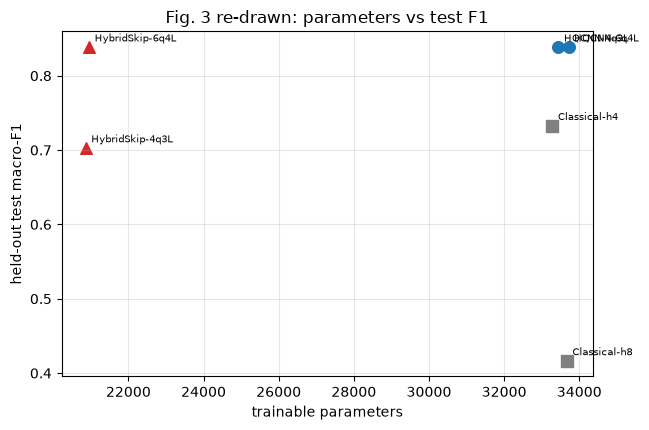

In [21]:
fam = {"Classical": ["Classical-h4", "Classical-h8"], "Std. HQCNN": ["HQCNN-4q3L", "HQCNN-6q4L"], "HybridSkip": ["HybridSkip-4q3L", "HybridSkip-6q4L"]}
rows5 = []
for fn, ms in fam.items():
    pp = [param_table.loc[m, "trainable params"] for m in ms]
    best = ms[-1]                                                  # the 6q4L / h8 member of each family, as in the paper's Table 5 text
    rows5.append({"family": fn, "params (range)": f"{min(pp):,}-{max(pp):,}", "CV F1 (largest model)": f"{cv_mean.loc[best,'f1']:.3f} +/- {cv[cv.model==best].f1.std():.3f}",
                  "test recall (largest model)": round(held.loc[best, 'rec'], 3),
                  "reduction vs Classical-h8": f"{(1 - param_table.loc[best,'trainable params']/param_table.loc['Classical-h8','trainable params'])*100:.1f} %"})
table5 = pd.DataFrame(rows5).set_index("family"); display(table5)

fig, ax = plt.subplots(figsize=(6.6, 4.4))
mk = {"classical": "s", "hqcnn": "o", "skip": "^"}; col = {"classical": "grey", "hqcnn": C_BEN, "skip": C_MAL}
for name in MODELS:
    kind = MODELS[name][0]
    ax.scatter(param_table.loc[name, "trainable params"], held.loc[name, "f1"], marker=mk[kind], c=col[kind], s=70)
    ax.annotate(name, (param_table.loc[name, "trainable params"], held.loc[name, "f1"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("trainable parameters"); ax.set_ylabel("held-out test macro-F1"); ax.set_title("Fig. 3 re-drawn: parameters vs test F1"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. Figures: cross-validation bars, learning curves, confusion matrices, learned angles

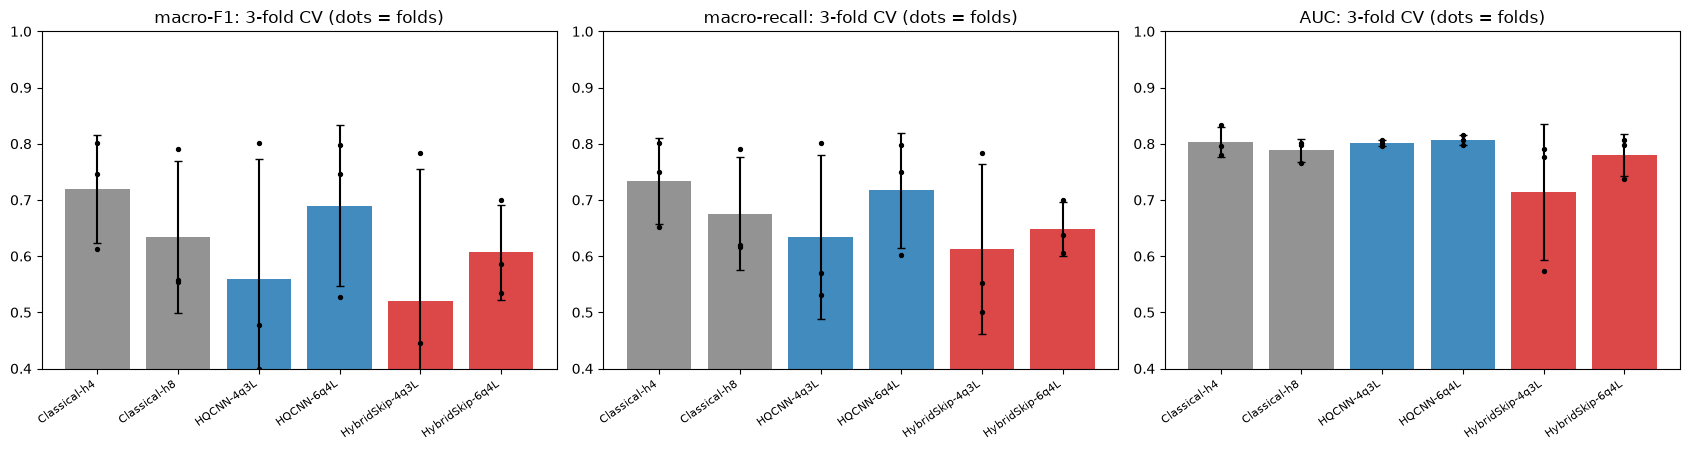

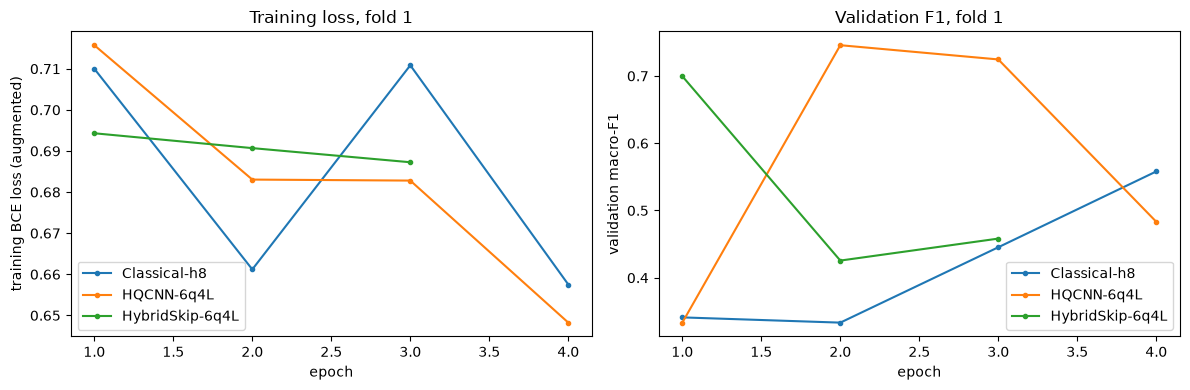

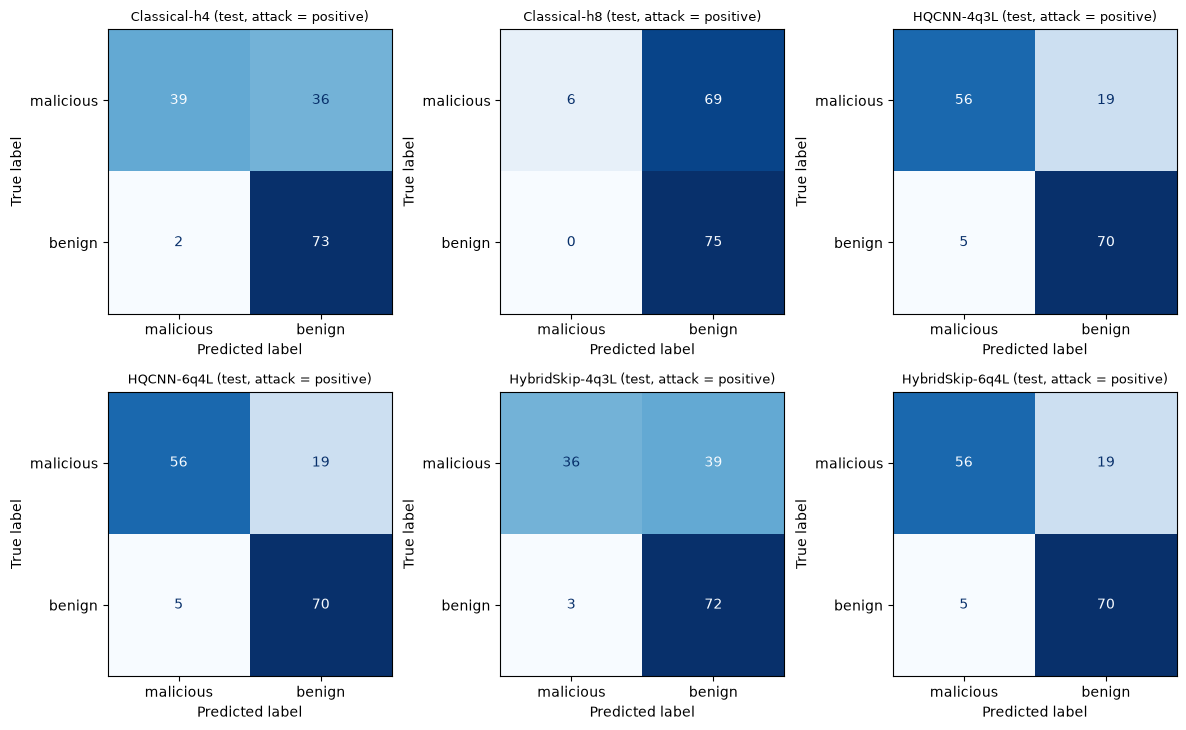

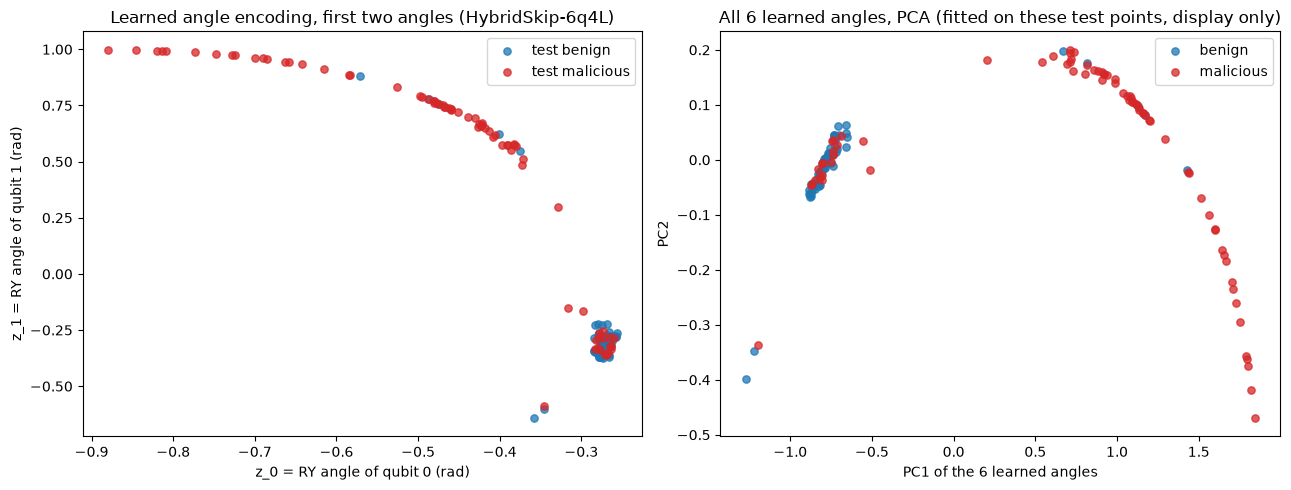

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
names = list(MODELS); xs = np.arange(len(names))
for j, (met, ttl) in enumerate([("f1", "macro-F1"), ("rec", "macro-recall"), ("auc", "AUC")]):
    mu = [cv[cv.model == n][met].mean() for n in names]; sd = [cv[cv.model == n][met].std() for n in names]
    axs[j].bar(xs, mu, yerr=sd, capsize=3, color=[col[MODELS[n][0]] for n in names], alpha=.85)
    for i, n in enumerate(names):
        axs[j].scatter([i] * len(cv[cv.model == n]), cv[cv.model == n][met], c="k", s=8, zorder=3)
    axs[j].set_xticks(xs); axs[j].set_xticklabels(names, rotation=35, ha="right", fontsize=8); axs[j].set_ylim(.4, 1.0); axs[j].set_title(f"{ttl}: {N_FOLDS}-fold CV (dots = folds)")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name in ["Classical-h8", "HQCNN-6q4L", "HybridSkip-6q4L"]:
    h = hist_store[(name, 0)]
    axs[0].plot(h.epoch, h.train_loss, marker="o", ms=3, label=name); axs[1].plot(h.epoch, h.val_f1, marker="o", ms=3, label=name)
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("training BCE loss (augmented)"); axs[0].set_title("Training loss, fold 1"); axs[0].legend()
axs[1].set_xlabel("epoch"); axs[1].set_ylabel("validation macro-F1"); axs[1].set_title("Validation F1, fold 1"); axs[1].legend()
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(12, 7.4))
for a, name in zip(axs.ravel(), MODELS):
    cm = confusion_matrix(y[idx_test], (held_prob[name] >= .5).astype(int), labels=[1, 0])        # malicious (positive) first
    ConfusionMatrixDisplay(cm, display_labels=["malicious", "benign"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name} (test, attack = positive)", fontsize=9)
plt.tight_layout(); plt.show()

# learned angles of the best hybrid model on the real test images
mdl = held_models["HybridSkip-6q4L"]; mdl.eval()
with torch.no_grad():
    Z = mdl.features(Xt[idx_test]).numpy()
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for lab, c in [(0, C_BEN), (1, C_MAL)]:
    m = y[idx_test] == lab
    axs[0].scatter(Z[m, 0], Z[m, 1], c=c, s=28, alpha=.75, label=f"test {CLASS_NAMES[lab]}")
axs[0].set_xlabel("z_0 = RY angle of qubit 0 (rad)"); axs[0].set_ylabel("z_1 = RY angle of qubit 1 (rad)"); axs[0].set_title("Learned angle encoding, first two angles (HybridSkip-6q4L)"); axs[0].legend()
pz = PCA(2, random_state=SEED).fit(Z)
Pz = pz.transform(Z)
for lab, c in [(0, C_BEN), (1, C_MAL)]:
    m = y[idx_test] == lab; axs[1].scatter(Pz[m, 0], Pz[m, 1], c=c, s=28, alpha=.75, label=CLASS_NAMES[lab])
axs[1].set_xlabel("PC1 of the 6 learned angles"); axs[1].set_ylabel("PC2"); axs[1].set_title("All 6 learned angles, PCA (fitted on these test points, display only)"); axs[1].legend()
plt.tight_layout(); plt.show()

## 10. Side by side with the paper

Verdict rule (from the project brief): "reproduced" when the notebook value is within 0.02 of the paper's (accuracy or F1 scale), otherwise "not reached" (ours lower) or
"exceeded" (ours higher), with the gap; "cannot be checked" when we have no basis for the comparison.

In [23]:
PAPER_CV = {"Classical-h4": (.638, .655, .621, .635, .662), "Classical-h8": (.670, .683, .665, .672, .687), "HQCNN-4q3L": (.652, .664, .678, .669, .695),
            "HQCNN-6q4L": (.685, .691, .718, .703, .719), "HybridSkip-4q3L": (.658, .669, .685, .676, .701), "HybridSkip-6q4L": (.683, .688, .710, .694, .706)}
PAPER_TEST = {"Classical-h4": (.633, .647, .615, .631, .658), "Classical-h8": (.667, .679, .655, .667, .698), "HQCNN-4q3L": (.667, .682, .692, .687, .712),
              "HQCNN-6q4L": (.700, .714, .714, .714, .735), "HybridSkip-4q3L": (.667, .679, .697, .688, .710), "HybridSkip-6q4L": (.700, .706, .724, .715, .728)}
MET = ["acc", "prec", "rec", "f1", "auc"]
def verdict(ours, paper, tol=0.02):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")

rows = []
for n in MODELS:
    for j, mt in enumerate(MET):
        rows.append({"table": "2 (CV)", "model": n, "metric": mt, "paper": PAPER_CV[n][j], "notebook": round(cv_mean.loc[n, mt], 3), "verdict": verdict(cv_mean.loc[n, mt], PAPER_CV[n][j])})
        rows.append({"table": "3 (test)", "model": n, "metric": mt, "paper": PAPER_TEST[n][j], "notebook": round(held.loc[n, mt], 3), "verdict": verdict(held.loc[n, mt], PAPER_TEST[n][j])})
tab = pd.DataFrame(rows)
summ = tab.assign(v=tab.verdict.str.split(" ").str[0]).groupby(["table", "v"]).size().unstack(fill_value=0)
print("Per-number verdicts, 2 tables x 6 models x 5 metrics (tolerance 0.02):"); display(summ)
display(tab.pivot_table(index="model", columns=["table", "metric"], values="notebook", sort=False).round(3))

Per-number verdicts, 2 tables x 6 models x 5 metrics (tolerance 0.02):


v,exceeded,not,reproduced
table,,,
2 (CV),14,10,6
3 (test),26,3,1


table,2 (CV),3 (test),2 (CV),3 (test),2 (CV),3 (test),2 (CV),3 (test),2 (CV),3 (test)
metric,acc,acc,prec,prec,rec,rec,f1,f1,auc,auc
model,,,,,,,,,,
Classical-h4,0.734,0.747,0.776,0.810,0.734,0.747,0.720,0.733,0.803,0.891
Classical-h8,0.675,0.540,0.774,0.760,0.676,0.540,0.635,0.417,0.788,0.852
HQCNN-4q3L,0.634,0.840,0.771,0.852,0.635,0.840,0.559,0.839,0.802,0.876
HQCNN-6q4L,0.716,0.840,0.784,0.852,0.717,0.840,0.690,0.839,0.807,0.866
HybridSkip-4q3L,0.612,0.720,0.591,0.786,0.612,0.720,0.520,0.703,0.714,0.880
HybridSkip-6q4L,0.648,0.840,0.750,0.852,0.648,0.840,0.607,0.839,0.781,0.855


In [24]:
# Claim-by-claim verdicts
cm_ = cv_mean
f1cv = lambda n: cm_.loc[n, "f1"]; reccv = lambda n: cm_.loc[n, "rec"]
sk, hq, c8 = "HybridSkip-6q4L", "HQCNN-6q4L", "Classical-h8"
rel_f1 = (f1cv(sk) / f1cv(c8) - 1) * 100; rel_rec = (reccv(sk) / reccv(c8) - 1) * 100
st_sk_rec = stat_table.loc[(f"{sk} vs {c8}", "Recall")]
red_ours = (1 - param_table.loc[sk, "trainable params"] / param_table.loc[c8, "trainable params"]) * 100
claims = []
def add(c, paper, ours, ok, extra=""):
    claims.append({"claim": c, "paper": paper, "notebook": ours, "verdict": ("reproduced" if ok else "not reached") if extra == "" else extra})
add("HybridSkip-6q4L CV F1 (Table 2)", ".694 +/- .027", f"{f1cv(sk):.3f} +/- {cv[cv.model==sk].f1.std():.3f}", abs(f1cv(sk) - .694) <= .02, "" if abs(f1cv(sk) - .694) <= .02 else verdict(f1cv(sk), .694))
add("HybridSkip-6q4L CV recall (Table 2)", ".710 +/- .031", f"{reccv(sk):.3f} +/- {cv[cv.model==sk].rec.std():.3f}", abs(reccv(sk) - .710) <= .02, "" if abs(reccv(sk) - .710) <= .02 else verdict(reccv(sk), .710))
add("HybridSkip-6q4L held-out F1 / recall (Table 3)", ".715 / .724", f"{held.loc[sk,'f1']:.3f} / {held.loc[sk,'rec']:.3f}", abs(held.loc[sk,'f1'] - .715) <= .02 and abs(held.loc[sk,'rec'] - .724) <= .02,
    "" if abs(held.loc[sk,'f1'] - .715) <= .02 and abs(held.loc[sk,'rec'] - .724) <= .02 else verdict(held.loc[sk,'f1'], .715) + " (F1)")
add("HybridSkip-6q4L CV F1 above Classical-h8 (+3.3 % rel.)", "+3.3 %", f"{rel_f1:+.1f} %", rel_f1 > 0 and abs(rel_f1 - 3.3) <= 3.0, "" if (rel_f1 > 0 and abs(rel_f1 - 3.3) <= 3.0) else ("exceeded (%+.1f %%)" % rel_f1 if rel_f1 > 3.3 else "not reached (%+.1f %%)" % rel_f1))
add("HybridSkip-6q4L CV recall above Classical-h8 (+6.8 % rel.)", "+6.8 %", f"{rel_rec:+.1f} %", rel_rec > 0 and abs(rel_rec - 6.8) <= 3.0, "" if (rel_rec > 0 and abs(rel_rec - 6.8) <= 3.0) else ("exceeded (%+.1f %%)" % rel_rec if rel_rec > 6.8 else "not reached (%+.1f %%)" % rel_rec))
add("Both quantum 6q4L models have higher CV recall than Classical-h8", "yes (.718, .710 vs .665)", f"{reccv(hq):.3f}, {reccv(sk):.3f} vs {reccv(c8):.3f}", reccv(hq) > reccv(c8) and reccv(sk) > reccv(c8))
add("6q4L beats 4q3L (CV F1) in both families", "yes", f"HQCNN {f1cv('HQCNN-6q4L'):.3f} vs {f1cv('HQCNN-4q3L'):.3f}; Skip {f1cv('HybridSkip-6q4L'):.3f} vs {f1cv('HybridSkip-4q3L'):.3f}",
    f1cv('HQCNN-6q4L') > f1cv('HQCNN-4q3L') and f1cv('HybridSkip-6q4L') > f1cv('HybridSkip-4q3L'))
add("HQCNN-6q4L has the highest raw CV F1 of the six", "yes (.703)", f"best = {cm_['f1'].idxmax()} ({cm_['f1'].max():.3f})", cm_['f1'].idxmax() == hq)
add("HybridSkip-6q4L recall gain significant: paired t-test p < .05, d > 0.8", "p = .014, d = 1.66", f"p = {st_sk_rec['t-test p']:.3f}, d = {st_sk_rec['Cohen d']:.2f}",
    st_sk_rec['t-test p'] < .05 and st_sk_rec['Cohen d'] > .8)
add("Wilcoxon (1-tailed) recall p = .031 (smallest attainable with 5 folds)", ".031", f"{st_sk_rec['Wilcoxon p (1-tail)']:.3f} (min attainable with {N_FOLDS} folds: {1/2**N_FOLDS:.3f})", st_sk_rec['Wilcoxon p (1-tail)'] <= .05)
add("HybridSkip-6q4L has lower fold std of F1 than Classical-h8 ('more stable')", ".027 vs .043", f"{cv[cv.model==sk].f1.std():.3f} vs {cv[cv.model==c8].f1.std():.3f}", cv[cv.model==sk].f1.std() < cv[cv.model==c8].f1.std())
claims.append({"claim": "HybridSkip-6q4L uses 37.6 % fewer parameters than Classical-h8 (21,015 vs 33,673)", "paper": "-37.6 %",
               "notebook": f"{param_table.loc[sk,'trainable params']:,} vs {param_table.loc[c8,'trainable params']:,} ({-red_ours:.1f} %)",
               "verdict": "cannot be checked independently (wide-head width and backbone widths were calibrated to the paper's totals; the literal Fig. 1 backbone gives ~148k parameters)"})
claims.append({"claim": "Quantum model gains come from the quantum block, not capacity (parameter-normalised comparison)", "paper": "asserted",
               "notebook": "see Section 11 (Classical-h8 vs HQCNN with matching parameter budget) ", "verdict": "see critical reading"})
claims_df = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 140); display(claims_df)
print("\nTotal wall time of this notebook run: %.1f min" % ((time.time() - T_NOTEBOOK) / 60))

,claim,paper,notebook,verdict
0,HybridSkip-6q4L CV F1 (Table 2),.694 +/- .027,0.607 +/- 0.084,not reached (-0.087)
1,HybridSkip-6q4L CV recall (Table 2),.710 +/- .031,0.648 +/- 0.048,not reached (-0.062)
2,HybridSkip-6q4L held-out F1 / recall (Table 3),.715 / .724,0.839 / 0.840,exceeded (+0.124) (F1)
3,HybridSkip-6q4L CV F1 above Classical-h8 (+3.3 % rel.),+3.3 %,-4.3 %,not reached (-4.3 %)
4,HybridSkip-6q4L CV recall above Classical-h8 (+6.8 % rel.),+6.8 %,-4.1 %,not reached (-4.1 %)
5,Both quantum 6q4L models have higher CV recall than Classical-h8,"yes (.718, .710 vs .665)","0.717, 0.648 vs 0.676",not reached
6,6q4L beats 4q3L (CV F1) in both families,yes,HQCNN 0.690 vs 0.559; Skip 0.607 vs 0.520,reproduced
7,HQCNN-6q4L has the highest raw CV F1 of the six,yes (.703),best = Classical-h4 (0.720),not reached
8,"HybridSkip-6q4L recall gain significant: paired t-test p < .05, d > 0.8","p = .014, d = 1.66","p = 0.766, d = -0.20",not reached
9,Wilcoxon (1-tailed) recall p = .031 (smallest attainable with 5 folds),.031,0.625 (min attainable with 3 folds: 0.125),not reached



Total wall time of this notebook run: 24.0 min


## 11. Reading the paper critically

**What this notebook's run is (and is not).** The committed outputs come from `FAST_MODE = True`: 3 folds, 4 epochs, patience 2, one seed. That is about 12 CPU-minutes
(24 minutes wall on a busy shared laptop) and the networks are clearly under-trained, so fold standard deviations are 0.05-0.2 and the *ranking of the six models is
noise*. The paper's budget (5 folds, up to 30 epochs, 36 fits) is roughly nine times more training steps (estimated 3-4 h on that machine, not run here). Treat the verdict tables as
"what a 4-epoch demo gives", not as a refutation of the paper's absolute numbers. What *can* be read off already:

1. **The data are real and the task is easy for a plain forest.** On the identical 48 x 48 inputs a random forest reaches CV F1 0.876 +/- 0.021 and test F1 0.907, an RBF-SVM 0.822 / 0.873,
   far above every deep model in the paper (F1 0.63-0.72) and above every model here. The paper has no non-deep baseline, so its remark that decode-free detection is "strictly
   harder" (Section 6.4) is a statement about its CNNs, not about the problem.
2. **Most of the signal is payload length.** A logistic regression on one number, the *original image side* (which fixes the QR version), gets CV F1 0.776 and test F1 0.839. Malicious
   payloads are longer, hence higher-version QR codes (see the version histogram). The 48 x 48 resize destroys the side length but keeps the module density, which is why a CNN
   can still use it, but a model that "learns the QR structure" is largely learning *how many modules there are*. The dataset has one rendering style (10 px modules, 4-module quiet zone),
   so this may be an artefact of how the benign and malicious sets were generated rather than of how real attacks look.
3. **The parameter claim is a design statement, not a quantum result.** The 37.6 % saving comes from replacing the *wide compensatory layer* of the head by a narrow 8-unit head. Any classical
   network with that narrow head has the same count (exercise 2). Moreover the quoted totals (21,015 / 33,673) cannot be produced by the Fig. 1 backbone (about 148,000 parameters here), so we had to
   calibrate the widths; the "-37.8 %" printed above is therefore a consequence of our calibration, not an independent confirmation.
4. **The cross-validation protocol is optimistic.** Fold metrics are computed on the same fold-validation set that picks the early-stopping checkpoint (best validation F1), and the five folds share most of
   their training data, so paired tests on five numbers (Table 4) violate the independence the t-test assumes. The paper's printed p-values do agree with its own confidence intervals (our check cell),
   but its Cohen's d does not equal the paired d_z implied by those intervals, so the effect-size definition is unclear. With 5 folds the smallest one-tailed Wilcoxon p is 0.031, so
   "p = .031" only says that all five differences had the same sign.
5. **No test of the quantum mechanism.** There is no ablation in which the circuit is replaced by an equally wide classical layer *inside* the skip architecture, no repeated seeds, and the circuit
   is noiseless. In HybridSkip the head receives `z` directly, so the model can ignore `q` altogether. In our runs the differences between Classical, HQCNN and HybridSkip are within fold noise
   (e.g. held-out F1 0.839 for HQCNN-6q4L and HybridSkip-6q4L but 0.417 for Classical-h8, which in this 4-epoch run simply collapsed towards the benign class: malicious recall 0.08).
6. **Paper-internal inconsistencies worth knowing.** Fig. 1 shows the standard HQCNN head as `FC n_q -> 8`, while the text says it uses a wide compensatory layer; Table 5 gives one count range for
   "Std. HQCNN" that does not match the 59.3 % overhead quoted in Section 5.2; the 4q3L and 6q4L parameter totals differ by more than the quantum block can explain.
7. **Scope.** One dataset of 1000 images and one QR style; no adversarial evaluation (an attacker can pad a payload to imitate benign module density), no real hardware, no noise.

## 12. Exercises

1. **Run the paper's budget.** Set `FAST_MODE = False` (5 folds, 30 epochs, patience 8) on a machine you can leave running for a few hours and compare Tables 2-4 again. Do the standard deviations shrink to the paper's 0.03-0.05? Does the ranking of the six models become stable?
2. **A classical model with the skip architecture's head.** Build "Classical-skip": the backbone, `Linear(n_q, n_q) + tanh` instead of the circuit, and the narrow `Linear(2 n_q, 8)` head. Count its parameters and run it through the same folds. Does it match HybridSkip? What does that say about the 37.6 % claim?
3. **Remove the quantum path.** In `QRNet.forward` for `kind == "skip"` feed `torch.zeros_like(q)` instead of `q`. If F1 does not change, what is the circuit contributing?
4. **Literal Fig. 1.** Set `WIDTHS = (32, 32, 64, 64, 128)` and `FC_HIDDEN = 64` and rerun. How do the parameter counts and the F1 values change? What would the wide-head width need to be to reach the paper's totals?
5. **The version shortcut.** Train the CNN on images whose QR *version* is hidden (for example crop every code to the 21 x 21 central modules or pad all codes to the same size before resizing) and compare with the random-forest and image-side baselines. How much of the accuracy survives?